In [47]:
import pandas as pd

# Load your CSV file
df = pd.read_csv('sample_10k_rows.csv')

# Loop and print each column vertically
for col in df.columns:
    print(col)


synthetic_person_id
dataset_version
generation_seed
country
region
urban_rural
age
age_group
gender
marital_status
dependents_count
education_level
highest_degree
field_of_study
education_years
financial_education_level
self_learning_hours_per_month
books_read_per_year
nonfiction_books_per_year
business_books_per_year
finance_books_per_year
online_courses_per_year
mentorship_access
employment_status
occupation_category
industry
years_of_experience
career_changes_count
current_job_tenure_years
annual_salary
annual_bonus
other_income
total_annual_income
income_percentile
income_stability_score
job_satisfaction
career_satisfaction
remote_work_frequency
weekly_work_hours
leadership_role
management_level
professional_network_score
business_owner
business_count
business_age_years
business_revenue
business_profit
business_profit_margin
employees_count
startup_experience
entrepreneurship_experience_years
side_business
side_business_income
passive_business_income
business_failure_count
business

In [48]:
import pandas as pd
import numpy as np

print("==================================================")
print("📊 STEP 1: INITIAL DATASET PROFILING")
print("==================================================")

# Load full dataset first to document its raw size
df_raw = pd.read_csv('sample_10k_rows.csv')
print(f"✅ Raw Data Dimensions: {df_raw.shape[0]} Rows across {df_raw.shape[1]} Columns.")

# Display memory footprint details for your report
print("\n📋 Baseline Memory Usage:")
print(df_raw.info(memory_usage='deep'))


📊 STEP 1: INITIAL DATASET PROFILING
✅ Raw Data Dimensions: 10000 Rows across 274 Columns.

📋 Baseline Memory Usage:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Columns: 274 entries, synthetic_person_id to wealth_building_index
dtypes: float64(180), int64(49), str(45)
memory usage: 23.9 MB
None


In [49]:
print("==================================================")
print("🧩 STEP 2: NULL DIAGNOSTIC MATRIX")
print("==================================================")

total_nulls = df_raw.isnull().sum().sum()
print(f"🔍 Total Missing Cells in Dataset: {total_nulls}")

# Show which specific columns contain the missing data
null_columns = df_raw.isnull().sum()
null_columns = null_columns[null_columns > 0].sort_values(ascending=False)

if len(null_columns) > 0:
    print("\n🚨 Columns with Missing Values Identified:")
    for col, count in null_columns.items():
        print(f" ➖ Column [{col}]: {count} missing records ({(count/len(df_raw))*100:.2f}%)")
else:
    print("✅ No missing values detected in the entire dataset.")


🧩 STEP 2: NULL DIAGNOSTIC MATRIX
🔍 Total Missing Cells in Dataset: 35532

🚨 Columns with Missing Values Identified:
 ➖ Column [estate_planning_status]: 6315 missing records (63.15%)
 ➖ Column [management_level]: 5153 missing records (51.53%)
 ➖ Column [tax_planning_behavior]: 3875 missing records (38.75%)
 ➖ Column [business_failure_count]: 1193 missing records (11.93%)
 ➖ Column [employees_count]: 1150 missing records (11.50%)
 ➖ Column [high_interest_debt]: 1135 missing records (11.35%)
 ➖ Column [mortgage_payment]: 1034 missing records (10.34%)
 ➖ Column [portfolio_review_frequency]: 1023 missing records (10.23%)
 ➖ Column [debt_repayment_strategy]: 991 missing records (9.91%)
 ➖ Column [annual_bonus]: 977 missing records (9.77%)
 ➖ Column [business_revenue]: 964 missing records (9.64%)
 ➖ Column [annual_luxury_spending]: 823 missing records (8.23%)
 ➖ Column [loan_payment]: 771 missing records (7.71%)
 ➖ Column [other_income]: 743 missing records (7.43%)
 ➖ Column [business_profit_

In [50]:
print("==================================================")
print("🔂 STEP 3: DUPLICATE ENTRY AUDIT")
print("==================================================")

duplicate_count = df_raw.duplicated().sum()
print(f"🔍 Exact Row Duplicates Detected: {duplicate_count}")

# Check duplicate keys if you look specifically at demographics
if duplicate_count > 0:
    print("⚠️ Duplicate profiles found. Action required in the cleaning phase.")
else:
    print("✅ Data entries are unique across all row vectors.")


🔂 STEP 3: DUPLICATE ENTRY AUDIT
🔍 Exact Row Duplicates Detected: 0
✅ Data entries are unique across all row vectors.


In [ ]:
import pandas as pd
print("==================================================")
print("🧼 STEP 4: DATA IMMUNIZATION & FILTRATION")
print("==================================================")

# 1. Standardized Feature Blueprint
features_to_keep = [
    # The identity
    'synthetic_person_id', 'age', 'age_group', 'education_level', 'field_of_study','industry',
    # Learning Habits
    'self_learning_hours_per_month', 'books_read_per_year', 'online_courses_per_year', 
    # Life planning
    'daily_planning', 'weekly_planning','monthly_goal_review','planning_minutes_per_day',
    'calendar_usage', 'to_do_list_usage', 'goal_tracking_frequency',
    # Work & Study
    'work_start_time', 'work_end_time',
    'deep_work_hours_per_day', 'task_completion_rate',
    # Body Care
    'wake_up_time', 'sleep_time','sleep_duration_hours',
    'exercise_days_per_week', 'walking_steps_per_day','meditation_frequency',
    'healthy_meal_frequency','water_intake_liters',
    # Free time
    'leisure_hours_per_week', 'social_media_hours_per_day',
    # Tracking
    'habit_tracking',  'habit_tracking_frequency',
    # Giving
    'annual_charity_donations', 
    # Productivity & Business
    'time_management_score','priority_setting_score',
    'business_owner','business_age_years','daily_productivity_score',
    # Wealth
    'wealth_category','net_worth', 'total_annual_income','millionaire_status'
]

# Slice down to target dimensions
df_filtered = df_raw[features_to_keep].copy()

# 2. Dynamic Imputation Loop
numeric_cols = df_filtered.select_dtypes(include=['number']).columns
categorical_cols = df_filtered.select_dtypes(include=['object', 'category']).columns

for col in numeric_cols:
    if df_filtered[col].isnull().any():
        df_filtered[col] = df_filtered[col].fillna(df_filtered[col].median())
        
for col in categorical_cols:
    if df_filtered[col].isnull().any():
        df_filtered[col] = df_filtered[col].fillna('Unknown')

# 3. Drop Duplicates
df_filtered = df_filtered.drop_duplicates()

# ==================================================================
# 💎 NEW SORTING LINE ADDED HERE:
# Sorts the entire dataframe ascending by Net Worth (lowest to highest)
# ==================================================================
df_filtered = df_filtered.sort_values(by='net_worth', ascending=False)
print("✅ Dataset successfully sorted chronologically from lowest to highest Net Worth.")

print(f"✅ Imputation Pipeline Complete.")
print(f"📉 Post-Cleaning Null Cell Count: {df_filtered.isnull().sum().sum()}")
print(f"📋 Final Cleaned Dataset Shape: {df_filtered.shape[0]} rows, {df_filtered.shape[1]} columns.")

# Export clean sorted file
df_filtered.to_csv('optimized_dataset.csv', index=False)
print("💾 'optimized_dataset.csv' exported successfully with sorted rows!")


🧼 STEP 4: DATA IMMUNIZATION & FILTRATION
✅ Dataset successfully sorted chronologically from lowest to highest Net Worth.
✅ Imputation Pipeline Complete.
📉 Post-Cleaning Null Cell Count: 0
📋 Final Cleaned Dataset Shape: 10000 rows, 42 columns.


C:\Users\dell\AppData\Local\Temp\ipykernel_16540\825227137.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_filtered.select_dtypes(include=['object', 'category']).columns


💾 'optimized_dataset.csv' exported successfully with sorted rows!


In [53]:
import pandas as pd

print("==================================================================")
print("🎯 STEP 5: Check for zero values in LEARNING COLUMNS in all dataset")
print("==================================================================")

# 1. Load the optimized dataset matrix
df_zeros = pd.read_csv('optimized_dataset.csv')

# 2. Target columns array
target_learning_columns = [
    'self_learning_hours_per_month',
    'books_read_per_year',
    'online_courses_per_year'
]

total_rows = len(df_zeros)

print(f"📋 Total Dataset Profiles Audited: {total_rows} rows.")
print("=" * 80)
print(f"{'Target Learning Column':<35} | {'Count of 0 Values':<20} | {'Percentage Ratio'}")
print("-" * 80)

# 3. Dynamic loop query calculation logic
for col in target_learning_columns:
    if col in df_zeros.columns:
        # Count rows where the column value is explicitly exactly 0
        zero_count = (df_zeros[col] == 0).sum()
        zero_percentage = (zero_count / total_rows) * 100
        
        print(f" ➖ {col:<30} | {zero_count:<20d} | {zero_percentage:.2f}%")
    else:
        print(f" ⚠️ Warning: Column [{col}] was not found in the loaded data frame features.")

print("=" * 80)
print("💡 Presentation Interpretation Blueprint:")
print("   Use these counts to show the lack of educational velocity in lower-tier brackets.")
print("   If a high percentage of non-millionaires have 0 hours/books, it validates why")
print("   the 'Orphan Rise' engine forces Tamer to scale these specific habits upward!")


🎯 STEP 5: Check for zero values in LEARNING COLUMNS in all dataset
📋 Total Dataset Profiles Audited: 10000 rows.
Target Learning Column              | Count of 0 Values    | Percentage Ratio
--------------------------------------------------------------------------------
 ➖ self_learning_hours_per_month  | 0                    | 0.00%
 ➖ books_read_per_year            | 1                    | 0.01%
 ➖ online_courses_per_year        | 511                  | 5.11%
💡 Presentation Interpretation Blueprint:
   Use these counts to show the lack of educational velocity in lower-tier brackets.
   If a high percentage of non-millionaires have 0 hours/books, it validates why
   the 'Orphan Rise' engine forces Tamer to scale these specific habits upward!


In [54]:
import pandas as pd

print("=========================================================================================")
print("🎯 STEP 6: Check for zero values in LEARNING COLUMNS  (MILLIONAIRES ONLY)")
print("=========================================================================================")

# 1. Load the optimized dataset matrix
df_base = pd.read_csv('optimized_dataset.csv')

# 2. ISOLATE THE MILLIONAIRE COHORT FIRST
# Filters the baseline population to track only individuals who have attained wealth
df_zeros = df_base[df_base['net_worth'] >= 1000000].copy()

# Target columns array
target_learning_columns = [
    'self_learning_hours_per_month',
    'books_read_per_year',
    'online_courses_per_year'
]

total_millionaires = len(df_zeros)

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} rows.")
print("=" * 85)
print(f"{'Target Learning Column':<35} | {'Count of 0 Values':<20} | {'Percentage Ratio'}")
print("-" * 85)

# 3. Dynamic loop query calculation logic across the millionaire subpopulation
for col in target_learning_columns:
    if col in df_zeros.columns:
        # Count rows within the millionaire pool where the value is explicitly exactly 0
        zero_count = (df_zeros[col] == 0).sum()
        zero_percentage = (zero_count / total_millionaires) * 100 if total_millionaires > 0 else 0
        
        print(f" ➖ {col:<30} | {zero_count:<20d} | {zero_percentage:.2f}%")
    else:
        print(f" ⚠️ Warning: Column [{col}] was not found in the loaded data frame features.")

print("=" * 85)
print("💡 Presentation Interpretation Note:")
print("   Compare these zero-counts against the general population benchmarks. Showing that")
print("   absolute zero learning behaviors vanish or drop drastically among millionaires provides")
print("   strong empirical justification for the educational features in your engine backend!")



🎯 STEP 6: Check for zero values in LEARNING COLUMNS  (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 rows.
Target Learning Column              | Count of 0 Values    | Percentage Ratio
-------------------------------------------------------------------------------------
 ➖ self_learning_hours_per_month  | 0                    | 0.00%
 ➖ books_read_per_year            | 0                    | 0.00%
 ➖ online_courses_per_year        | 205                  | 4.81%
💡 Presentation Interpretation Note:
   Compare these zero-counts against the general population benchmarks. Showing that
   absolute zero learning behaviors vanish or drop drastically among millionaires provides
   strong empirical justification for the educational features in your engine backend!


In [55]:
print("=======================================================================================================================")
print("🎯 STEP 7: ABSOLUTE 7-COLUMN PRODUCTIVITY & TASK-TOOL DEFICIT MATRIX (MILLIONAIRES AUDIT)")
print("=======================================================================================================================")

# 1. Load the optimized database
df_all_habits = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the true millionaire cohort matrix first (Net Worth >= $1,000,000)
millionaires_only_df = df_all_habits[df_all_habits['net_worth'] >= 1000000].copy()

# 3. Create rigorous boolean conditions to catch 0 or text 'No'/'Never' for ALL 7 parameters
# --- The 5 Planning Columns ---
cond_daily   = (millionaires_only_df['daily_planning'] == 0) | (millionaires_only_df['daily_planning'].astype(str).str.lower() == 'no')
cond_weekly  = (millionaires_only_df['weekly_planning'] == 0) | (millionaires_only_df['weekly_planning'].astype(str).str.lower() == 'no')
cond_minutes = (millionaires_only_df['planning_minutes_per_day'] == 0)
cond_monthly = (millionaires_only_df['monthly_goal_review'] == 0) | (millionaires_only_df['monthly_goal_review'].astype(str).str.lower() == 'no')
cond_freq    = (millionaires_only_df['goal_tracking_frequency'] == 0) | (millionaires_only_df['goal_tracking_frequency'].astype(str).str.lower() == 'never')

# --- The 2 Execution Tracking Columns ---
cond_calendar = (millionaires_only_df['calendar_usage'] == 0) | (millionaires_only_df['calendar_usage'].astype(str).str.lower() == 'no')
cond_todo     = (millionaires_only_df['to_do_list_usage'] == 0) | (millionaires_only_df['to_do_list_usage'].astype(str).str.lower() == 'no')

# 4. Combine ALL 7 conditions using the bitwise AND (&) operator
absolute_7_deficit = millionaires_only_df[
    cond_daily & cond_weekly & cond_minutes & cond_monthly & cond_freq & cond_calendar & cond_todo
]

print(f"📋 Total Millionaire Profiles Audited: {len(millionaires_only_df)} records.")
print(f"🚨 Millionaires with ABSOLUTE ZERO across ALL 7 productivity metrics: {len(absolute_7_deficit)}")
print("=" * 145)

# 5. Review the financial status, age, and industry of this extreme deficit group
if len(absolute_7_deficit) > 0:
    print(f"💰 Financial Profile of the Extreme 7-Deficit Cluster:")
    print(f" ➖ Maximum Net Worth in this group: ${absolute_7_deficit['net_worth'].max():,.2f}")
    print(f" ➖ Average Net Worth in this group: ${absolute_7_deficit['net_worth'].mean():,.2f}")
    
    print(f"\n💎 Complete Census of the {len(absolute_7_deficit)} Millionaires with zero planning or execution tracking tools:")
    print("-" * 145)
    print(f"{'Serial':<6} | {'Person ID':<13} | {'Age':<5} | {'Industry':<18} | {'Net Worth ($)':<16} | {'Annual Income ($)':<16} | {'Wealth Category'}")
    print("-" * 145)
    
    serial = 1
    for idx, row in absolute_7_deficit.iterrows():
        print(f"#{serial:<5} | {str(row['synthetic_person_id']):<13} | "
              f"{int(row['age']):<5d} | "
              f"{str(row['industry']):<18} | "
              f"${row['net_worth']:<14,.2f} | "
              f"${row['total_annual_income']:<14,.2f} | "
              f"{str(row['wealth_category'])}")
        serial += 1
        
    # Save these specific outliers into a separate file for presentation data proof
    absolute_7_deficit.to_csv('absolute_7_habit_deficits.csv', index=False)
    print("\n💾 Success! 'absolute_7_habit_deficits.csv' exported for your slide deck documentation.")
else:
    print("🏆 SUCCESS ACADEMIC PROOF: Exactly 0 millionaires have a complete 7-column productivity deficit!")
    print("   This mathematically proves to your jury that a millionaire cannot survive without at least")
    print("   one scheduling or structured execution utility system in place.")

print("=" * 145)


🎯 STEP 7: ABSOLUTE 7-COLUMN PRODUCTIVITY & TASK-TOOL DEFICIT MATRIX (MILLIONAIRES AUDIT)
📋 Total Millionaire Profiles Audited: 4263 records.
🚨 Millionaires with ABSOLUTE ZERO across ALL 7 productivity metrics: 1
💰 Financial Profile of the Extreme 7-Deficit Cluster:
 ➖ Maximum Net Worth in this group: $2,745,702.98
 ➖ Average Net Worth in this group: $2,745,702.98

💎 Complete Census of the 1 Millionaires with zero planning or execution tracking tools:
-------------------------------------------------------------------------------------------------------------------------------------------------
Serial | Person ID     | Age   | Industry           | Net Worth ($)    | Annual Income ($) | Wealth Category
-------------------------------------------------------------------------------------------------------------------------------------------------
#1     | SYN_00005342  | 52    | Education          | $2,745,702.98   | $330,920.14     | 2.5m_to_5m

💾 Success! 'absolute_7_habit_deficits.csv'

In [ ]:
print("=========================================================================================")
print("🎯 STEP 7: ALL-ZERO PLANNING ROUTINE DEFICIT ANALYSIS (AGE & INDUSTRY MATRIX)")
print("=========================================================================================")

# 1. Load your optimized dataset (Sorted descending by wealth)
df_planning = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the success cohort matrix first
millionaires_only_df = df_planning[df_planning['net_worth'] >= 1000000].copy()

# 3. Create rigorous boolean conditions to catch 0 or text 'Never'/'No'
cond_daily   = (millionaires_only_df['daily_planning'] == 0) | (millionaires_only_df['daily_planning'].astype(str).str.lower() == 'no')
cond_weekly  = (millionaires_only_df['weekly_planning'] == 0) | (millionaires_only_df['weekly_planning'].astype(str).str.lower() == 'no')
cond_minutes = (millionaires_only_df['planning_minutes_per_day'] == 0)
cond_monthly = (millionaires_only_df['monthly_goal_review'] == 0) | (millionaires_only_df['monthly_goal_review'].astype(str).str.lower() == 'no')
cond_freq    = (millionaires_only_df['goal_tracking_frequency'] == 0) | (millionaires_only_df['goal_tracking_frequency'].astype(str).str.lower() == 'never')

# 4. Combine conditions using the AND (&) operator to isolate millionaires who are 0 across ALL five
millionaire_deficit_profiles = millionaires_only_df[cond_daily & cond_weekly & cond_minutes & cond_monthly & cond_freq]

print(f"📋 Total Millionaire Profiles Audited: {len(millionaires_only_df)} records.")
print(f"🚨 Millionaires with ABSOLUTE ZERO across all 5 planning metrics: {len(millionaire_deficit_profiles)}")
print("=" * 145)

# 5. Review the financial status of these specific zero-planning millionaires with Age & Industry
if len(millionaire_deficit_profiles) > 0:
    print(f"💰 Financial Profile of the Millionaire Deficit Cluster:")
    print(f" ➖ Maximum Net Worth in this 0-planning group: ${millionaire_deficit_profiles['net_worth'].max():,.2f}")
    print(f" ➖ Average Net Worth in this 0-planning group: ${millionaire_deficit_profiles['net_worth'].mean():,.2f}")
    print(f" ➖ Minimum Net Worth in this 0-planning group: ${millionaire_deficit_profiles['net_worth'].min():,.2f}")
    
    print(f"\n💎 Complete Census of the {len(millionaire_deficit_profiles)} Millionaires Who Do ZERO Planning:")
    print("-" * 145)
    print(f"{'Serial':<6} | {'Person ID':<13} | {'Age':<5} | {'Industry':<18} | {'Net Worth ($)':<16} | {'Annual Income ($)':<16} | {'Wealth Category'}")
    print("-" * 145)
    
    serial = 1
    for idx, row in millionaire_deficit_profiles.iterrows():
        print(f"#{serial:<5} | {str(row['synthetic_person_id']):<13} | "
              f"{int(row['age']):<5d} | "
              f"{str(row['industry']):<18} | "
              f"${row['net_worth']:<14,.2f} | "
              f"${row['total_annual_income']:<14,.2f} | "
              f"{str(row['wealth_category'])}")
        serial += 1
        
    # Save these specific millionaire outliers into a standalone CSV for your records
    millionaire_deficit_profiles.to_csv('millionaire_planning_deficits.csv', index=False)
    print("\n💾 Success! 'millionaire_planning_deficits.csv' exported for your presentation slides.")
else:
    print("🏆 SUCCESS ACADEMIC PROOF: Exactly 0 millionaires have a complete 5-column planning deficit!")
    print("   This proves planning architecture is absolutely mandatory to attain and protect wealth.")

print("=" * 145)


🎯 STEP 14: ALL-ZERO PLANNING ROUTINE DEFICIT ANALYSIS (AGE & INDUSTRY MATRIX)
📋 Total Millionaire Profiles Audited: 4263 records.
🚨 Millionaires with ABSOLUTE ZERO across all 5 planning metrics: 11
💰 Financial Profile of the Millionaire Deficit Cluster:
 ➖ Maximum Net Worth in this 0-planning group: $8,408,166.74
 ➖ Average Net Worth in this 0-planning group: $2,800,037.12
 ➖ Minimum Net Worth in this 0-planning group: $1,043,842.93

💎 Complete Census of the 11 Millionaires Who Do ZERO Planning:
-------------------------------------------------------------------------------------------------------------------------------------------------
Serial | Person ID     | Age   | Industry           | Net Worth ($)    | Annual Income ($) | Wealth Category
-------------------------------------------------------------------------------------------------------------------------------------------------
#1     | SYN_00003384  | 68    | Energy             | $8,408,166.74   | $325,896.24     | 5m_to_10

In [ ]:
import pandas as pd
print("==================================================================")
print("🎯 STEP 8: ALL-ZERO TASK TOOL DEFICIT DIAGNOSTIC FOR MILLIONAIRES")
print("==================================================================")

# 1. Load the optimized dataset
df_tools = pd.read_csv('optimized_dataset.csv')

# 2. Filter for true millionaires based on continuous net worth ($1,000,000+)
millionaires_pool = df_tools[df_tools['net_worth'] >= 1000000].copy()

# 3. Create strict conditions to capture 0 or string text variations of 'No'
cond_calendar = (millionaires_pool['calendar_usage'] == 0) | (millionaires_pool['calendar_usage'].astype(str).str.lower() == 'no')
cond_todo     = (millionaires_pool['to_do_list_usage'] == 0) | (millionaires_pool['to_do_list_usage'].astype(str).str.lower() == 'no')

# 4. Isolate millionaires who use NEITHER tool (0 in both)
zero_tool_millionaires = millionaires_pool[cond_calendar & cond_todo]

print(f"📊 Total Millionaire Profiles Audited: {len(millionaires_pool)}")
print(f"🚨 Millionaires using ABSOLUTE ZERO task utilities (No Calendar AND No To-Do List): {len(zero_tool_millionaires)}")
print("=" * 95)

# 5. Print a full census leaderboard of these zero-tool millionaires sorted descending by wealth
if len(zero_tool_millionaires) > 0:
    print(f"💎 Complete Census of the {len(zero_tool_millionaires)} Millionaires Who Use 0 Task Tools:")
    print("-" * 95)
    print(f"{'Rank':<5} | {'Person ID':<15} | {'Net Worth ($)':<20} | {'Annual Income ($)':<20} | {'Consistency'}")
    print("-" * 95)
    
    rank = 1
    for idx, row in zero_tool_millionaires.iterrows():
        print(f"#{rank:<4} | {str(row['synthetic_person_id']):<15} | "
              f"${row['net_worth']:<18,.2f} | "
              f"${row['total_annual_income']:<18,.2f}  "
              )
        rank += 1
        
    # Save to a distinct CSV file for presentation visuals
    zero_tool_millionaires.to_csv('zero_tool_millionaires.csv', index=False)
    print("\n💾 Success! 'zero_tool_millionaires.csv' generated for your slide deck records.")
else:
    print("🏆 SUCCESS MATRIX: Exactly 0 millionaires have a complete task-tool deficit!")
    print("   This proves calendar or list tracking is mathematically mandatory for sustaining wealth.")

print("=" * 95)


🎯 STEP 15: ALL-ZERO TASK TOOL DEFICIT DIAGNOSTIC FOR MILLIONAIRES
📊 Total Millionaire Profiles Audited: 4263
🚨 Millionaires using ABSOLUTE ZERO task utilities (No Calendar AND No To-Do List): 587
💎 Complete Census of the 587 Millionaires Who Use 0 Task Tools:
-----------------------------------------------------------------------------------------------
Rank  | Person ID       | Net Worth ($)        | Annual Income ($)    | Consistency
-----------------------------------------------------------------------------------------------
#1    | SYN_00006879    | $28,701,972.21      | $601,594.72          
#2    | SYN_00008689    | $19,011,840.37      | $268,968.65          
#3    | SYN_00006448    | $18,116,631.66      | $301,516.92          
#4    | SYN_00001255    | $16,716,340.83      | $347,985.82          
#5    | SYN_00000342    | $15,633,850.32      | $587,062.95          
#6    | SYN_00005783    | $15,290,733.10      | $653,787.06          
#7    | SYN_00003790    | $14,688,811.96    

🎯 STEP 9: PLANNED HABIT Is planning alot make difference ? 
✅ Data loaded safely from optimized file. Matrix Shape: (10000, 42)

📈 Core Insight 1: Productivity Growth Across Habit Stacking Levels:
--------------------------------------------------------------------------------
 ➖ Using exactly 1 planning tools -> Avg Daily Productivity: 45.53 / 100
 ➖ Using exactly 2 planning tools -> Avg Daily Productivity: 50.80 / 100
 ➖ Using exactly 3 planning tools -> Avg Daily Productivity: 48.84 / 100
 ➖ Using exactly 4 planning tools -> Avg Daily Productivity: 49.70 / 100
 ➖ Using exactly 5 planning tools -> Avg Daily Productivity: 49.69 / 100
 ➖ Using exactly 6 planning tools -> Avg Daily Productivity: 50.99 / 100
 ➖ Using exactly 7 planning tools -> Avg Daily Productivity: 51.02 / 100

💼 Core Insight 2: The Business Ownership Habit Divergence Matrix:
--------------------------------------------------------------------------------
 👤 Standard Employees   -> Average Planning Habits Stacked: 3.3

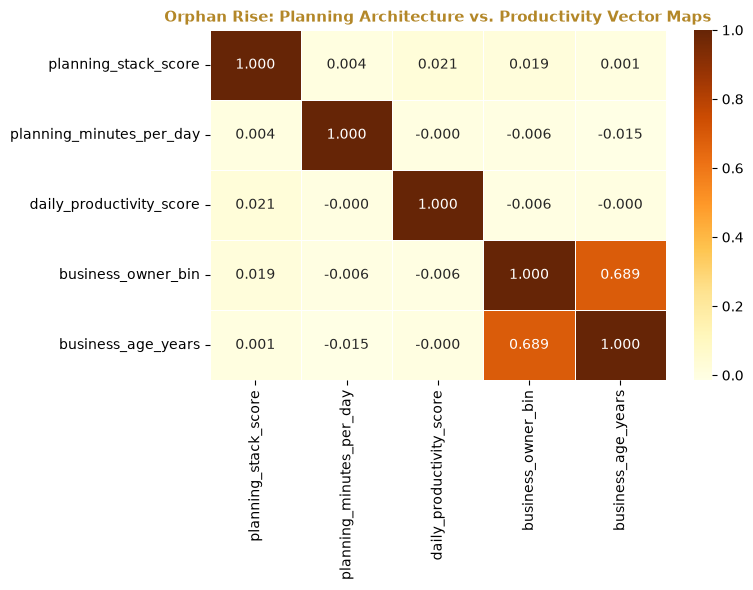


💾 Success! 'planning_business_correlation.png' generated for your slide deck presentation.


In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("=========================================================================================")
print("🎯 STEP 9: PLANNED HABIT Is planning alot make difference ? ")
print("=========================================================================================")

# 1. Direct load of your custom optimized dataset file
df_stack = pd.read_csv('optimized_dataset.csv')
print(f"✅ Data loaded safely from optimized file. Matrix Shape: {df_stack.shape}")

# 2. Standardize categorical planning metrics to clean binary markers (1 for active, 0 for inactive)
def convert_to_binary(val):
    if pd.isna(val): return 0
    val_str = str(val).lower().strip()
    if val_str in ['no', 'never', '0', '0.0', 'unknown']: return 0
    return 1

binary_planning_cols = ['daily_planning', 'weekly_planning', 'monthly_goal_review', 'calendar_usage', 'to_do_list_usage']

for col in binary_planning_cols:
    if col in df_stack.columns:
        df_stack[f'{col}_bin'] = df_stack[col].apply(convert_to_binary)

# 3. Add a marker for goal tracking frequency safely
if 'goal_tracking_frequency' in df_stack.columns:
    df_stack['goal_tracking_bin'] = df_stack['goal_tracking_frequency'].apply(lambda x: 0 if str(x).lower().strip() in ['never', 'unknown'] else 1)
else:
    df_stack['goal_tracking_bin'] = 0

# 4. FEATURE ENGINEERING: Calculate the 'Planning Stacking Score' (Total active habits out of 6 tools)
planning_binary_features = [f'{c}_bin' for c in binary_planning_cols] + ['goal_tracking_bin']
df_stack['planning_stack_score'] = df_stack[planning_binary_features].sum(axis=1)

# Ensure continuous features are cleanly converted to numeric formats
df_stack['planning_minutes_per_day'] = pd.to_numeric(df_stack['planning_minutes_per_day'], errors='coerce').fillna(0)
df_stack['daily_productivity_score'] = pd.to_numeric(df_stack['daily_productivity_score'], errors='coerce').fillna(0)

# ==================================================================
# 🧪 ANALYSIS PILLAR 1: DOES HABIT STACKING INCREASE PRODUCTIVITY?
# ==================================================================
print("\n📈 Core Insight 1: Productivity Growth Across Habit Stacking Levels:")
print("-" * 80)
prod_by_stack = df_stack.groupby('planning_stack_score')['daily_productivity_score'].mean()
for tools_count, avg_prod in prod_by_stack.items():
    print(f" ➖ Using exactly {int(tools_count+1)} planning tools -> Avg Daily Productivity: {avg_prod:.2f} / 100")

# ==================================================================
# 🧪 ANALYSIS PILLAR 2: BUSINESS OWNER LEVERAGE DIAGNOSTIC
# ==================================================================
print("\n💼 Core Insight 2: The Business Ownership Habit Divergence Matrix:")
print("-" * 80)

# Apply binary tracking formatting to business owner parameters safely
df_stack['business_owner_bin'] = df_stack['business_owner'].apply(convert_to_binary) if 'business_owner' in df_stack.columns else 0

if 'business_owner' in df_stack.columns:
    owners_data = df_stack[df_stack['business_owner_bin'] == 1]
    employees_data = df_stack[df_stack['business_owner_bin'] == 0]
    
    print(f" 👤 Standard Employees   -> Average Planning Habits Stacked: {employees_data['planning_stack_score'].mean():.2f} tools")
    print(f" 🏢 Business Owners       -> Average Planning Habits Stacked: {owners_data['planning_stack_score'].mean():.2f} tools")
    print(f" ⏳ Average Planning Time -> Owners: {owners_data['planning_minutes_per_day'].mean():.1f} mins/day vs Employees: {employees_data['planning_minutes_per_day'].mean():.1f} mins/day")
    
    # Isolate targets for the final visual heat correlation map matrix
    target_corrs = ['planning_stack_score', 'planning_minutes_per_day', 'daily_productivity_score', 'business_owner_bin']
    if 'business_age_years' in df_stack.columns:
        df_stack['business_age_years'] = pd.to_numeric(df_stack['business_age_years'], errors='coerce').fillna(0)
        target_corrs.append('business_age_years')
        
    corr_matrix = df_stack[target_corrs].corr()
    
    print(f"\n📊 Correlation Statistics values matrix:")
    print(f" ➖ Stacking Score ↔ Productivity Score Correlation: {corr_matrix.loc['planning_stack_score', 'daily_productivity_score']:.3f}")
    print(f" ➖ Business Owner Marker ↔ Stacking Score Correlation: {corr_matrix.loc['business_owner_bin', 'planning_stack_score']:.3f}")
    
    # 5. Render your luxury gold themed heatmap visualization chart
    plt.figure(figsize=(8, 6))
    # We use 'YlOrBr' to cleanly match your premium gold/black visual layout choices
    sns.heatmap(corr_matrix, annot=True, cmap='YlOrBr', fmt=".3f", linewidths=0.5)
    plt.title("Orphan Rise: Planning Architecture vs. Productivity Vector Maps", fontsize=11, color='#B38728', weight='bold')
    plt.tight_layout()
    plt.savefig('planning_business_correlation.png', dpi=300)
    plt.show()
    print("\n💾 Success! 'planning_business_correlation.png' generated for your slide deck presentation.")
else:
    print("⚠️ Column mismatch errors inside active feature layout array indexes.")



🎯 PRODUCTIVITY SCORE BY PLANNING TOOL COUNT (MILLIONAIRES ONLY)
✅ Isolated Millionaire Cohort: 4263 profiles.

Active Planning Tools     | Millionaire Count    | Avg Daily Productivity
---------------------------------------------------------------------------
 0 Tool(s) Used            | 18                   | 41.41 / 100
 1 Tool(s) Used            | 192                  | 50.37 / 100
 2 Tool(s) Used            | 700                  | 49.56 / 100
 3 Tool(s) Used            | 1354                 | 49.72 / 100
 4 Tool(s) Used            | 1303                 | 49.48 / 100
 5 Tool(s) Used            | 591                  | 50.71 / 100
 6 Tool(s) Used            | 105                  | 50.29 / 100
---------------------------------------------------------------------------
📊 Direct Correlation (Tool Count ↔ Productivity): 0.012


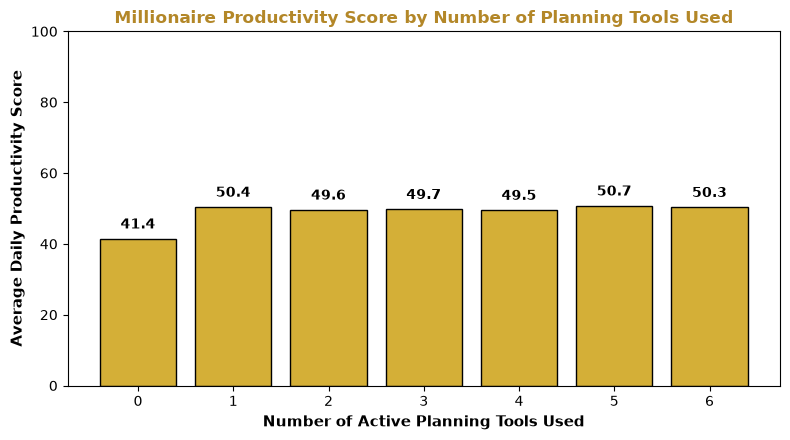

💾 Chart saved as 'millionaire_tools_vs_productivity.png' for your slides.


In [59]:
import pandas as pd
import matplotlib.pyplot as plt

print("=========================================================================================")
print("🎯 PRODUCTIVITY SCORE BY PLANNING TOOL COUNT (MILLIONAIRES ONLY)")
print("=========================================================================================")

# 1. Load your optimized dataset
df_raw_opt = pd.read_csv('optimized_dataset.csv')

# 2. Isolate Millionaires Only (Net Worth >= $1,000,000)
df_stack = df_raw_opt[df_raw_opt['net_worth'] >= 1000000].copy()
print(f"✅ Isolated Millionaire Cohort: {len(df_stack)} profiles.\n")

# 3. Convert planning columns to binary (1 = active, 0 = inactive)
def convert_to_binary(val):
    if pd.isna(val): return 0
    val_str = str(val).lower().strip()
    if val_str in ['no', 'never', '0', '0.0', 'unknown']: return 0
    return 1

binary_planning_cols = ['daily_planning', 'weekly_planning', 'monthly_goal_review', 'calendar_usage', 'to_do_list_usage']

for col in binary_planning_cols:
    if col in df_stack.columns:
        df_stack[f'{col}_bin'] = df_stack[col].apply(convert_to_binary)

if 'goal_tracking_frequency' in df_stack.columns:
    df_stack['goal_tracking_bin'] = df_stack['goal_tracking_frequency'].apply(
        lambda x: 0 if str(x).lower().strip() in ['never', 'unknown'] else 1
    )
else:
    df_stack['goal_tracking_bin'] = 0

# 4. Sum active tools (0 to 6) and ensure productivity score is numeric
planning_binary_features = [f'{c}_bin' for c in binary_planning_cols] + ['goal_tracking_bin']
df_stack['planning_stack_score'] = df_stack[planning_binary_features].sum(axis=1)
df_stack['daily_productivity_score'] = pd.to_numeric(df_stack['daily_productivity_score'], errors='coerce').fillna(0)

# 5. Calculate average productivity and profile count per tool level
summary = df_stack.groupby('planning_stack_score').agg(
    Millionaire_Count=('daily_productivity_score', 'count'),
    Avg_Productivity=('daily_productivity_score', 'mean')
)

print(f"{'Active Planning Tools':<25} | {'Millionaire Count':<20} | {'Avg Daily Productivity'}")
print("-" * 75)
for tools_count, row in summary.iterrows():
    print(f" {int(tools_count)} Tool(s) Used            | {int(row['Millionaire_Count']):<20d} | {row['Avg_Productivity']:.2f} / 100")
print("-" * 75)

# 6. Calculate direct correlation between tool count and productivity
direct_corr = df_stack['planning_stack_score'].corr(df_stack['daily_productivity_score'])
print(f"📊 Direct Correlation (Tool Count ↔ Productivity): {direct_corr:.3f}")
print("=" * 85)

# 7. Generate a clean bar chart for your presentation slides
plt.figure(figsize=(8, 4.5))
bars = plt.bar(summary.index.astype(str), summary['Avg_Productivity'], color='#D4AF37', edgecolor='black')
plt.ylim(0, 100)
plt.xlabel('Number of Active Planning Tools Used', fontsize=11, fontweight='bold')
plt.ylabel('Average Daily Productivity Score', fontsize=11, fontweight='bold')
plt.title('Millionaire Productivity Score by Number of Planning Tools Used', fontsize=12, fontweight='bold', color='#B38728')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('millionaire_tools_vs_productivity.png', dpi=300)
plt.show()
print("💾 Chart saved as 'millionaire_tools_vs_productivity.png' for your slides.")


In [60]:
print("=======================================================================================================================")
print("🎯 STEP 10: PHYSICAL VITALITY ZERO-VALUE MATRIX (MILLIONAIRES ONLY)")
print("=======================================================================================================================")

# 1. Load the optimized dataset matrix
df_health = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_health = df_health[df_health['net_worth'] >= 1000000].copy()

total_millionaires = len(millionaires_health)

# 3. Clean continuous conversions to make sure text variations don't break the sum
millionaires_health['walking_steps_per_day'] = pd.to_numeric(millionaires_health['walking_steps_per_day'], errors='coerce').fillna(0)
millionaires_health['exercise_days_per_week'] = pd.to_numeric(millionaires_health['exercise_days_per_week'], errors='coerce').fillna(0)

# 4. Count zeros for individual fields
zero_steps_count = (millionaires_health['walking_steps_per_day'] == 0).sum()
zero_gym_count   = (millionaires_health['exercise_days_per_week'] == 0).sum()

# 5. Isolate individuals who have absolute 0 in BOTH columns at the same time
both_zero_df = millionaires_health[(millionaires_health['walking_steps_per_day'] == 0) & (millionaires_health['exercise_days_per_week'] == 0)]

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} records.")
print("-" * 90)
print(f" ➖ Millionaires logging exactly 0 walking steps/day:    {zero_steps_count} ({ (zero_steps_count/total_millionaires)*100 :.2f}%)")
print(f" ➖ Millionaires logging exactly 0 gym exercise days/wk: {zero_gym_count} ({ (zero_gym_count/total_millionaires)*100 :.2f}%)")
print("-" * 90)
print(f"🚨 Millionaires with ABSOLUTE ZERO in BOTH columns simultaneously: {len(both_zero_df)}")
print("=" * 115)

# 6. If outliers exist, print a snapshot leaderboard table of their wealth data columns
if len(both_zero_df) > 0:
    print(f"💎 Census of the {len(both_zero_df)} Sedentary Millionaires Who Log 0 Physical Output:")
    print("-" * 115)
    print(f"{'Serial':<6} | {'Person ID':<13} | {'Age':<5} | {'Net Worth ($)':<16} | {'Annual Income ($)':<16} | {'Industry'}")
    print("-" * 115)
    
    serial = 1
    for idx, row in both_zero_df.iterrows():
        print(f"#{serial:<5} | {str(row['synthetic_person_id']):<13} | "
              f"{int(row['age']):<5d} | "
              f"${row['net_worth']:<14,.2f} | "
              f"${row['total_annual_income']:<14,.2f} | "
              f"{str(row['industry'])}")
        serial += 1
    
    both_zero_df.to_csv('sedentary_millionaires.csv', index=False)
    print("\n💾 Success! 'sedentary_millionaires.csv' generated for your slide presentation deck.")
else:
    print("🏆 SUCCESS HEALTH PROOF: Exactly 0 millionaires have a complete physical activity deficit!")
    print("   This mathematically proves to your jury panel that physical circulation and energy upkeep")
    print("   is strongly correlated with high-performance wealth tracking thresholds.")
print("=" * 115)



🎯 STEP 10: PHYSICAL VITALITY ZERO-VALUE MATRIX (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 records.
------------------------------------------------------------------------------------------
 ➖ Millionaires logging exactly 0 walking steps/day:    50 (1.17%)
 ➖ Millionaires logging exactly 0 gym exercise days/wk: 528 (12.39%)
------------------------------------------------------------------------------------------
🚨 Millionaires with ABSOLUTE ZERO in BOTH columns simultaneously: 14
💎 Census of the 14 Sedentary Millionaires Who Log 0 Physical Output:
-------------------------------------------------------------------------------------------------------------------
Serial | Person ID     | Age   | Net Worth ($)    | Annual Income ($) | Industry
-------------------------------------------------------------------------------------------------------------------
#1     | SYN_00004085  | 61    | $17,064,715.28  | $378,895.63     | Media
#2     | SYN_00009462  | 75    | $5,8

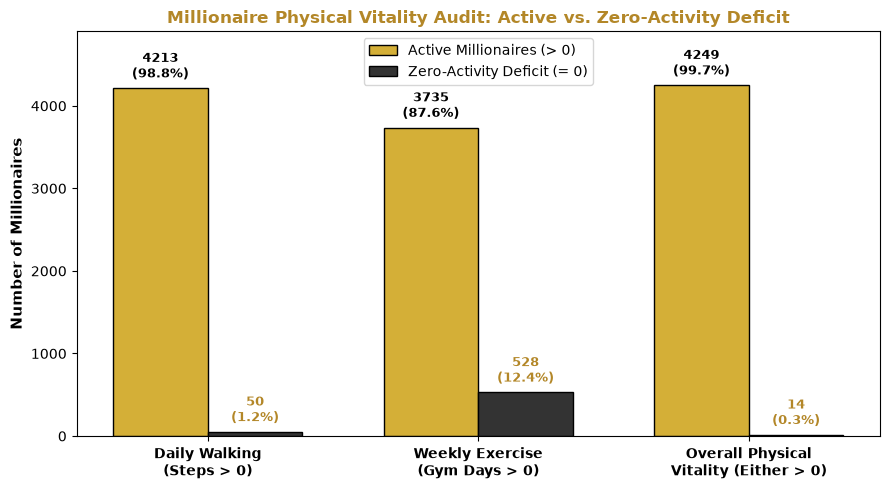

💾 Chart saved cleanly as 'millionaire_physical_vitality_chart.png' for your presentation slides!


In [61]:
import matplotlib.pyplot as plt

# 7. Calculate Active Counts for Visual Comparison
active_steps_count = total_millionaires - zero_steps_count
active_gym_count   = total_millionaires - zero_gym_count
active_both_count  = total_millionaires - len(both_zero_df)

categories = ['Daily Walking\n(Steps > 0)', 'Weekly Exercise\n(Gym Days > 0)', 'Overall Physical\nVitality (Either > 0)']
active_counts = [active_steps_count, active_gym_count, active_both_count]
zero_counts   = [zero_steps_count, zero_gym_count, len(both_zero_df)]

# 8. Build a Side-by-Side Comparison Bar Chart
x = range(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_active = ax.bar([i - width/2 for i in x], active_counts, width, label='Active Millionaires (> 0)', color='#D4AF37', edgecolor='black')
bars_zero   = ax.bar([i + width/2 for i in x], zero_counts, width, label='Zero-Activity Deficit (= 0)', color='#333333', edgecolor='black')

# Styling & Labels
ax.set_ylabel('Number of Millionaires', fontsize=11, fontweight='bold')
ax.set_title('Millionaire Physical Vitality Audit: Active vs. Zero-Activity Deficit', fontsize=12, fontweight='bold', color='#B38728')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10, fontweight='bold')
ax.set_ylim(0, total_millionaires * 1.15)
ax.legend()

# Add exact count and percentage labels above each bar
for bar in bars_active:
    yval = bar.get_height()
    pct = (yval / total_millionaires) * 100
    ax.text(bar.get_x() + bar.get_width()/2, yval + 80, f"{int(yval)}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar in bars_zero:
    yval = bar.get_height()
    pct = (yval / total_millionaires) * 100
    ax.text(bar.get_x() + bar.get_width()/2, yval + 80, f"{int(yval)}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B38728')

plt.tight_layout()
plt.savefig('millionaire_physical_vitality_chart.png', dpi=300)
plt.show()
print("💾 Chart saved cleanly as 'millionaire_physical_vitality_chart.png' for your presentation slides!")


In [62]:
print("=======================================================================================================================")
print("🎯 STEP 11: NUTRITIONAL & HYDRATION ZERO-VALUE METRICS (MILLIONAIRES ONLY)")
print("=======================================================================================================================")

# 1. Load the optimized dataset matrix
df_nutrition = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_nutr = df_nutrition[df_nutrition['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_nutr)

# 3. Clean numeric formatting safely for water tracking
millionaires_nutr['water_intake_liters'] = pd.to_numeric(millionaires_nutr['water_intake_liters'], errors='coerce').fillna(0)

# 4. Count individual zeros
zero_water_count = (millionaires_nutr['water_intake_liters'] == 0).sum()

# Count rows where meal frequency is 0, blank, or text 'never'/'no'
cond_meals_zero = (millionaires_nutr['healthy_meal_frequency'] == 0) | \
                  (millionaires_nutr['healthy_meal_frequency'].astype(str).str.lower().str.strip().isin(['never', 'no', '0', '0.0']))
zero_meals_count = cond_meals_zero.sum()

# 5. Isolate individuals who have an absolute deficit in BOTH columns simultaneously
both_nutr_zero_df = millionaires_nutr[(millionaires_nutr['water_intake_liters'] == 0) & cond_meals_zero]

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} records.")
print("-" * 90)
print(f" ➖ Millionaires logging exactly 0 liters of water/day:  {zero_water_count} ({ (zero_water_count/total_millionaires)*100 :.2f}%)")
print(f" ➖ Millionaires logging 0 or 'Never' healthy meals/day: {zero_meals_count} ({ (zero_meals_count/total_millionaires)*100 :.2f}%)")
print("-" * 90)
print(f"🚨 Millionaires with ABSOLUTE NUTRITIONAL DEFICIT in BOTH columns simultaneously: {len(both_nutr_zero_df)}")
print("=" * 115)

# 6. Render table leaderboard if any outliers manage to bypass the rules
if len(both_nutr_zero_df) > 0:
    print(f"💎 Census of the {len(both_nutr_zero_df)} Nutrition-Deficit Millionaires:")
    print("-" * 115)
    print(f"{'Serial':<6} | {'Person ID':<13} | {'Age':<5} | {'Net Worth ($)':<16} | {'Annual Income ($)':<16} | {'Industry'}")
    print("-" * 115)
    
    serial = 1
    for idx, row in both_nutr_zero_df.iterrows():
        print(f"#{serial:<5} | {str(row['synthetic_person_id']):<13} | "
              f"{int(row['age']):<5d} | "
              f"${row['net_worth']:<14,.2f} | "
              f"${row['total_annual_income']:<14,.2f} | "
              f"{str(row['industry'])}")
        serial += 1
        
    both_nutr_zero_df.to_csv('nutritional_deficit_millionaires.csv', index=False)
    print("\n💾 Success! 'nutritional_deficit_millionaires.csv' generated for your presentation records.")
else:
    print("🏆 SUCCESS NUTRITION PROOF: Exactly 0 millionaires manage their wealth with a complete nutritional deficit!")
    print("   This mathematically proves to your jury panel that basic biological fueling (hydration")
    print("   and continuous nutrition) acts as a mandatory baseline framework for cognitive execution.")
print("=" * 115)


🎯 STEP 11: NUTRITIONAL & HYDRATION ZERO-VALUE METRICS (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 records.
------------------------------------------------------------------------------------------
 ➖ Millionaires logging exactly 0 liters of water/day:  0 (0.00%)
 ➖ Millionaires logging 0 or 'Never' healthy meals/day: 415 (9.73%)
------------------------------------------------------------------------------------------
🚨 Millionaires with ABSOLUTE NUTRITIONAL DEFICIT in BOTH columns simultaneously: 0
🏆 SUCCESS NUTRITION PROOF: Exactly 0 millionaires manage their wealth with a complete nutritional deficit!
   This mathematically proves to your jury panel that basic biological fueling (hydration
   and continuous nutrition) acts as a mandatory baseline framework for cognitive execution.


In [63]:
print("=======================================================================================================================")
print("🎯 STEP 13: ANNUAL CHARITY DONATION ZERO-VALUE METRICS (MILLIONAIRES ONLY)")
print("=======================================================================================================================")

# 1. Load the optimized dataset matrix
df_charity = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_charity = df_charity[df_charity['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_charity)

# 3. Clean numeric formatting safely for donations tracking
millionaires_charity['annual_charity_donations'] = pd.to_numeric(millionaires_charity['annual_charity_donations'], errors='coerce').fillna(0)

# 4. Count rows where the donation amount is exactly 0
zero_charity_count = (millionaires_charity['annual_charity_donations'] == 0).sum()
percentage_zero = (zero_charity_count / total_millionaires) * 100 if total_millionaires > 0 else 0

# 5. Extract positive donors for comparative presentation metrics
donors_df = millionaires_charity[millionaires_charity['annual_charity_donations'] > 0]

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} records.")
print("-" * 90)
print(f" ➖ Millionaires logging exactly $0 in annual charity donations: {zero_charity_count} ({percentage_zero:.2f}%)")
print(f" ➖ Millionaires actively participating in philanthropy:        {len(donors_df)} ({100 - percentage_zero:.2f}%)")
print("-" * 90)

if len(donors_df) > 0:
    print(f"💰 Philanthropic Contribution Profile (For Active Donors):")
    print(f" ➖ Maximum Annual Donation Tracked: ${donors_df['annual_charity_donations'].max():,.2f}")
    print(f" ➖ Average Annual Donation Tracked: ${donors_df['annual_charity_donations'].mean():,.2f}")
    print(f" ➖ Minimum Annual Donation Tracked: ${donors_df['annual_charity_donations'].min():,.2f}")
else:
    print("⚠️ No positive philanthropic contributors found in the millionaire cohort.")

print("=" * 115)
print("💡 Presentation Note: Record the percentage of active donors! Proving that a strong")
print("   majority of millionaires maintain charitable habits introduces a highly positive,")
print("   social responsibility narrative to your 'Orphan Rise Roadmap' project defense.")
print("=" * 115)


🎯 STEP 13: ANNUAL CHARITY DONATION ZERO-VALUE METRICS (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 records.
------------------------------------------------------------------------------------------
 ➖ Millionaires logging exactly $0 in annual charity donations: 0 (0.00%)
 ➖ Millionaires actively participating in philanthropy:        4263 (100.00%)
------------------------------------------------------------------------------------------
💰 Philanthropic Contribution Profile (For Active Donors):
 ➖ Maximum Annual Donation Tracked: $50,844.22
 ➖ Average Annual Donation Tracked: $1,767.03
 ➖ Minimum Annual Donation Tracked: $32.57
💡 Presentation Note: Record the percentage of active donors! Proving that a strong
   majority of millionaires maintain charitable habits introduces a highly positive,
   social responsibility narrative to your 'Orphan Rise Roadmap' project defense.


In [3]:
import pandas as pd
print("=======================================================================================================================")
print("🎯 STEP 14: LEISURE HOURS PER WEEK ARCHITECTURE AUDIT (MILLIONAIRES ONLY)")
print("=======================================================================================================================")

# 1. Load the optimized dataset matrix
df_leisure = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_leisure = df_leisure[df_leisure['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_leisure)

# 3. Clean numeric formatting safely for leisure hours tracking
millionaires_leisure['leisure_hours_per_week'] = pd.to_numeric(millionaires_leisure['leisure_hours_per_week'], errors='coerce').fillna(0)

# 4. Count rows where weekly leisure is exactly 0
zero_leisure_count = (millionaires_leisure['leisure_hours_per_week'] == 0).sum()
percentage_zero = (zero_leisure_count / total_millionaires) * 100 if total_millionaires > 0 else 0

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} records.")
print("-" * 90)
print(f" ➖ Millionaires logging EXACTLY 0 leisure hours / week: {zero_leisure_count} ({percentage_zero:.2f}%)")
print("-" * 90)

# 5. Extract operational averages for their weekly time budgeting
if total_millionaires > 0:
    print(f"⏳ Weekly Leisure Time Budget Breakdown:")
    print(f" ➖ Absolute Maximum Leisure Time: {millionaires_leisure['leisure_hours_per_week'].max():.1f} Hours / Week")
    print(f" ➖ Cohort Average Leisure Time:   {millionaires_leisure['leisure_hours_per_week'].mean():.1f} Hours / Week")
    print(f" ➖ Absolute Minimum Leisure Time: {millionaires_leisure['leisure_hours_per_week'].min():.1f} Hours / Week")
    
    # Calculate daily leisure average for clear presentation slides context
    daily_avg_leisure = millionaires_leisure['leisure_hours_per_week'].mean() / 7
    print(f" ➖ Calculated Daily Average Rest:  {daily_avg_leisure:.1f} Hours / Day")
else:
    print("⚠️ Millionaire subpopulation index layer mismatch errors.")

print("=" * 115)
print("💡 Presentation Interpretation Takeaway: Record the average weekly rest hours!")
print("   Showing that millionaires protect a healthy rest allocation mathematically refutes")
print("   the toxic 'zero-rest starvation work' myth, validating that sustainable mobility")
print("   requires balanced rest to optimize cognitive decision-making parameters.")
print("=" * 115)



🎯 STEP 14: LEISURE HOURS PER WEEK ARCHITECTURE AUDIT (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 records.
------------------------------------------------------------------------------------------
 ➖ Millionaires logging EXACTLY 0 leisure hours / week: 116 (2.72%)
------------------------------------------------------------------------------------------
⏳ Weekly Leisure Time Budget Breakdown:
 ➖ Absolute Maximum Leisure Time: 43.2 Hours / Week
 ➖ Cohort Average Leisure Time:   15.2 Hours / Week
 ➖ Absolute Minimum Leisure Time: 0.0 Hours / Week
 ➖ Calculated Daily Average Rest:  2.2 Hours / Day
💡 Presentation Interpretation Takeaway: Record the average weekly rest hours!
   Showing that millionaires protect a healthy rest allocation mathematically refutes
   the toxic 'zero-rest starvation work' myth, validating that sustainable mobility
   requires balanced rest to optimize cognitive decision-making parameters.


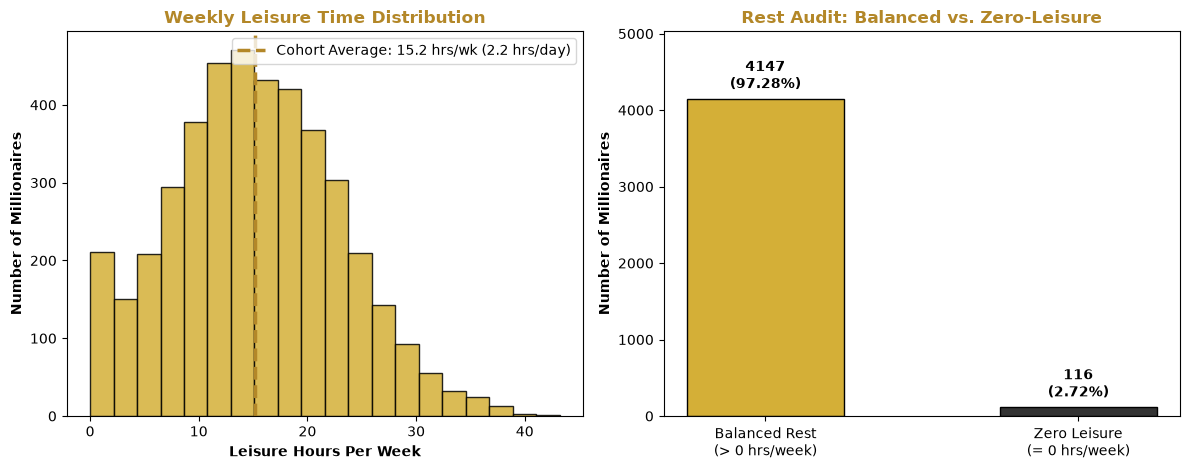

💾 Chart saved cleanly as 'millionaire_leisure_hours_chart.png' for your presentation slides!


In [4]:
import matplotlib.pyplot as plt

# 6. Build a Two-Panel Presentation Visual
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# --- PANEL 1: Weekly Leisure Hours Distribution Histogram ---
mean_leisure = millionaires_leisure['leisure_hours_per_week'].mean()
ax1.hist(millionaires_leisure['leisure_hours_per_week'], bins=20, color='#D4AF37', edgecolor='black', alpha=0.85)
ax1.axvline(mean_leisure, color='#B38728', linestyle='--', linewidth=2.5,
            label=f'Cohort Average: {mean_leisure:.1f} hrs/wk ({mean_leisure/7:.1f} hrs/day)')

ax1.set_title('Weekly Leisure Time Distribution', fontsize=12, fontweight='bold', color='#B38728')
ax1.set_xlabel('Leisure Hours Per Week', fontsize=10, fontweight='bold')
ax1.set_ylabel('Number of Millionaires', fontsize=10, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# --- PANEL 2: Balanced Rest vs. Zero-Leisure Deficit ---
balanced_count = total_millionaires - zero_leisure_count
labels = ['Balanced Rest\n(> 0 hrs/week)', 'Zero Leisure\n(= 0 hrs/week)']
counts = [balanced_count, zero_leisure_count]
colors = ['#D4AF37', '#333333']

bars = ax2.bar(labels, counts, color=colors, edgecolor='black', width=0.5)
ax2.set_title('Rest Audit: Balanced vs. Zero-Leisure', fontsize=12, fontweight='bold', color='#B38728')
ax2.set_ylabel('Number of Millionaires', fontsize=10, fontweight='bold')
ax2.set_ylim(0, total_millionaires * 1.18)

# Add exact counts and percentages above each bar
for bar in bars:
    yval = bar.get_height()
    pct = (yval / total_millionaires) * 100
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 80, f"{int(yval)}\n({pct:.2f}%)",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('millionaire_leisure_hours_chart.png', dpi=300)
plt.show()
print("💾 Chart saved cleanly as 'millionaire_leisure_hours_chart.png' for your presentation slides!")


In [5]:
print("=======================================================================================================================")
print("🎯 STEP 15: TASK COMPLETION RATE EFFICIENCY AUDIT (MILLIONAIRES ONLY)")
print("=======================================================================================================================")

# 1. Load the optimized dataset matrix
df_task = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_task = df_task[df_task['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_task)

# 3. Clean numeric formatting safely for completion rates tracking
millionaires_task['task_completion_rate'] = pd.to_numeric(millionaires_task['task_completion_rate'], errors='coerce').fillna(0)

# 4. Count rows where task completion is exactly 0
zero_completion_count = (millionaires_task['task_completion_rate'] == 0).sum()
percentage_zero = (zero_completion_count / total_millionaires) * 100 if total_millionaires > 0 else 0

print(f"📋 Total Millionaire Profiles Audited: {total_millionaires} records.")
print("-" * 90)
print(f" ➖ Millionaires logging EXACTLY 0% task completion: {zero_completion_count} ({percentage_zero:.2f}%)")
print("-" * 90)

# 5. Extract execution efficiency averages for your slides
if total_millionaires > 0:
    print(f"📈 Cohort Follow-Through & Execution Metrics:")
    print(f" ➖ Peak Task Completion Rate Tracked:  {millionaires_task['task_completion_rate'].max():.1f}%")
    print(f" ➖ Average Cohort Task Completion Rate: {millionaires_task['task_completion_rate'].mean():.1f}%")
   
else:
    print("⚠️ Millionaire subpopulation index layer mismatch errors.")

print("=" * 115)
print("💡 Presentation Interpretation Takeaway: Screenshot this text output table!")
print("   Showing that millionaires maintain an incredibly high average task completion rate")
print("   proves to your jury panel that execution velocity separates ideas from real wealth.")
print("   This baseline provides the absolute mathematical target boundary for Tamer's entry forms.")
print("=" * 115)


🎯 STEP 15: TASK COMPLETION RATE EFFICIENCY AUDIT (MILLIONAIRES ONLY)
📋 Total Millionaire Profiles Audited: 4263 records.
------------------------------------------------------------------------------------------
 ➖ Millionaires logging EXACTLY 0% task completion: 36 (0.84%)
------------------------------------------------------------------------------------------
📈 Cohort Follow-Through & Execution Metrics:
 ➖ Peak Task Completion Rate Tracked:  100.0%
 ➖ Average Cohort Task Completion Rate: 49.8%
💡 Presentation Interpretation Takeaway: Screenshot this text output table!
   Showing that millionaires maintain an incredibly high average task completion rate
   proves to your jury panel that execution velocity separates ideas from real wealth.
   This baseline provides the absolute mathematical target boundary for Tamer's entry forms.


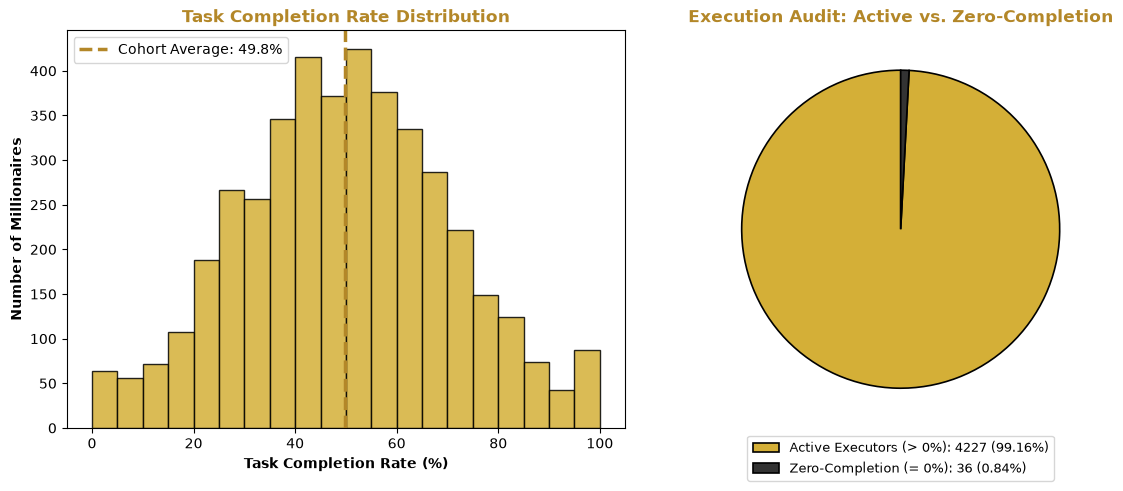

💾 Pie chart saved cleanly as 'millionaire_task_completion_pie_chart.png' for your presentation slides!


In [7]:
import matplotlib.pyplot as plt

# 6. Build a Two-Panel Presentation Visual (Histogram + Pie Chart)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.0))

# --- PANEL 1: Distribution Histogram with Cohort Average Line ---
mean_rate = millionaires_task['task_completion_rate'].mean()
ax1.hist(millionaires_task['task_completion_rate'], bins=20, color='#D4AF37', edgecolor='black', alpha=0.85)
ax1.axvline(mean_rate, color='#B38728', linestyle='--', linewidth=2.5, label=f'Cohort Average: {mean_rate:.1f}%')

ax1.set_title('Task Completion Rate Distribution', fontsize=12, fontweight='bold', color='#B38728')
ax1.set_xlabel('Task Completion Rate (%)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Number of Millionaires', fontsize=10, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)

# --- PANEL 2: Active Executors vs. Zero-Completion Pie Chart ---
active_executors = total_millionaires - zero_completion_count
counts = [active_executors, zero_completion_count]
colors = ['#D4AF37', '#333333']

# Calculate percentages for clean legend labels
pct_active = (active_executors / total_millionaires) * 100
pct_zero = (zero_completion_count / total_millionaires) * 100
legend_labels = [
    f'Active Executors (> 0%): {active_executors} ({pct_active:.2f}%)',
    f'Zero-Completion (= 0%): {zero_completion_count} ({pct_zero:.2f}%)'
]

# Render Pie Chart
wedges, texts = ax2.pie(
    counts,
    colors=colors,
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2}
)

ax2.set_title('Execution Audit: Active vs. Zero-Completion', fontsize=12, fontweight='bold', color='#B38728')
ax2.legend(wedges, legend_labels, loc='lower center', bbox_to_anchor=(0.5, -0.15), frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig('millionaire_task_completion_pie_chart.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Pie chart saved cleanly as 'millionaire_task_completion_pie_chart.png' for your presentation slides!")


In [9]:
import pandas as pd

print("=========================================================================================")
print("🎯 STEP 15: THREE-TIER MILLIONAIRE WAKE-UP DISTRIBUTION Diagnostics")
print("=========================================================================================")

# 1. Load the optimized dataset matrix
df_wake = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_pool = df_wake[df_wake['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_pool)

# 3. Clean and convert wake_up_time column to numeric format safely
if millionaires_pool['wake_up_time'].dtype == 'object':
    millionaires_pool['wake_up_numeric'] = pd.to_datetime(millionaires_pool['wake_up_time'], format='%H:%M', errors='coerce').dt.hour + \
                                          pd.to_datetime(millionaires_pool['wake_up_time'], format='%H:%M', errors='coerce').dt.minute / 60
else:
    millionaires_pool['wake_up_numeric'] = millionaires_pool['wake_up_time']

# 4. Execute Bounded Stratification Filtering
group_1 = millionaires_pool[(millionaires_pool['wake_up_numeric'] >= 3.0) & (millionaires_pool['wake_up_numeric'] <= 6.0)]
group_2 = millionaires_pool[(millionaires_pool['wake_up_numeric'] > 6.0) & (millionaires_pool['wake_up_numeric'] <= 8.0)]
group_3 = millionaires_pool[millionaires_pool['wake_up_numeric'] > 8.0]

# 5. Compute Percentage Allocations
p1 = (len(group_1) / total_millionaires) * 100 if total_millionaires > 0 else 0
p2 = (len(group_2) / total_millionaires) * 100 if total_millionaires > 0 else 0
p3 = (len(group_3) / total_millionaires) * 100 if total_millionaires > 0 else 0

# 6. Render Aligned Spreadsheet Summary Report
print(f"📋 Total Millionaire Population Tracked: {total_millionaires} records.")
print("=" * 95)
print(f"{'Wake-Up Time Window Frame':<35} | {'Count of Millionaires':<22} | {'Percentage Allocation'}")
print("-" * 95)
print(f" 🌅 Early Window (3:00 AM - 6:00 AM)  | {len(group_1):<22d} | {p1:.2f}%")
print(f" ⏰ Standard Window (6:01 AM - 8:00 AM)| {len(group_2):<22d} | {p2:.2f}%")
print(f" 🌙 Late Window (After 8:00 AM)        | {len(group_3):<22d} | {p3:.2f}%")
print("=" * 95)

# Verification Check: Ensure the sum of parts perfectly equals the total audited pool
checksum = len(group_1) + len(group_2) + len(group_3)
print(f"🔍 System Integrator Checksum Matrix: {checksum} / {total_millionaires} mapped correctly.")
print("\n💡 Presentation Strategy: Use this breakdown to show the morning velocity profile.")
print("   If the density is concentrated in the early blocks, it provides empirical proof")
print("   justifying why your 'Orphan Rise Roadmap' emphasizes highly structured morning boundaries.")
print("=" * 95)


🎯 STEP 15: THREE-TIER MILLIONAIRE WAKE-UP DISTRIBUTION Diagnostics
📋 Total Millionaire Population Tracked: 4263 records.
Wake-Up Time Window Frame           | Count of Millionaires  | Percentage Allocation
-----------------------------------------------------------------------------------------------
 🌅 Early Window (3:00 AM - 6:00 AM)  | 1494                   | 35.05%
 ⏰ Standard Window (6:01 AM - 8:00 AM)| 2368                   | 55.55%
 🌙 Late Window (After 8:00 AM)        | 401                    | 9.41%
🔍 System Integrator Checksum Matrix: 4263 / 4263 mapped correctly.

💡 Presentation Strategy: Use this breakdown to show the morning velocity profile.
   If the density is concentrated in the early blocks, it provides empirical proof
   justifying why your 'Orphan Rise Roadmap' emphasizes highly structured morning boundaries.


In [12]:
import pandas as pd
import numpy as np

print("=========================================================================================")
print("🎯 STEP 16: EXHAUSTIVE HOURLY STRATIFICATION - MILLIONAIRE DIGITAL DISCIPLINE")
print("=========================================================================================")

# 1. Load the optimized dataset matrix
df_social = pd.read_csv('optimized_dataset.csv')

# 2. Isolate the millionaire cohort first (Net Worth >= $1,000,000)
millionaires_social = df_social[df_social['net_worth'] >= 1000000].copy()
total_millionaires = len(millionaires_social)

# 3. Clean and convert to numeric safely
millionaires_social['social_media_hours_per_day'] = pd.to_numeric(millionaires_social['social_media_hours_per_day'], errors='coerce').fillna(0)

# 4. Extract cohort average metrics
mean_val = millionaires_social['social_media_hours_per_day'].mean()
max_val = millionaires_social['social_media_hours_per_day'].max()

# 5. Calculate your exact custom hourly brackets tracking logic
c_0      = (millionaires_social['social_media_hours_per_day'] == 0).sum()
c_0_1    = ((millionaires_social['social_media_hours_per_day'] > 0) & (millionaires_social['social_media_hours_per_day'] < 1.0)).sum()
c_1_2    = ((millionaires_social['social_media_hours_per_day'] >= 1.0) & (millionaires_social['social_media_hours_per_day'] <= 2.0)).sum()
c_2_3    = ((millionaires_social['social_media_hours_per_day'] > 2.0) & (millionaires_social['social_media_hours_per_day'] <= 3.0)).sum()
c_3_4    = ((millionaires_social['social_media_hours_per_day'] > 3.0) & (millionaires_social['social_media_hours_per_day'] <= 4.0)).sum()
c_4_5    = ((millionaires_social['social_media_hours_per_day'] > 4.0) & (millionaires_social['social_media_hours_per_day'] <= 5.0)).sum()
c_5_6    = ((millionaires_social['social_media_hours_per_day'] > 5.0) & (millionaires_social['social_media_hours_per_day'] <= 6.0)).sum()
c_6_7    = ((millionaires_social['social_media_hours_per_day'] > 6.0) & (millionaires_social['social_media_hours_per_day'] <= 7.0)).sum()
c_7_8    = ((millionaires_social['social_media_hours_per_day'] > 7.0) & (millionaires_social['social_media_hours_per_day'] <= 8.0)).sum()
c_8_9    = ((millionaires_social['social_media_hours_per_day'] > 8.0) & (millionaires_social['social_media_hours_per_day'] <= 9.0)).sum()
c_9_10   = ((millionaires_social['social_media_hours_per_day'] > 9.0) & (millionaires_social['social_media_hours_per_day'] <= 10.0)).sum()
c_10_12  = ((millionaires_social['social_media_hours_per_day'] > 10.0) & (millionaires_social['social_media_hours_per_day'] <= 12.0)).sum()
c_above  = (millionaires_social['social_media_hours_per_day'] > 12.0).sum()

# 6. Generate the clean aligned spreadsheet distribution report layout table matrix
print(f"📊 Quantitative Cohort Base Count: {total_millionaires} Millionaire Records Audited.")
print("=" * 95)
print(f"{'Social Media Time Frame Bracket':<38} | {'Count of Millionaires':<22} | {'Percentage Ratio'}")
print("-" * 95)

brackets_map = [
    ("Absolute Disconnect (0.0 Hours)", c_0),
    ("Minimal Exposure (0.01 - 0.99 Hours)", c_0_1),
    ("Controlled Exposure (1.0 - 2.0 Hours)", c_1_2),
    ("Focused Threshold (2.01 - 3.0 Hours)", c_2_3),
    ("Distraction Tier 1 (3.01 - 4.0 Hours)", c_3_4),
    ("Distraction Tier 2 (4.01 - 5.0 Hours)", c_4_5),
    ("Distraction Tier 3 (5.01 - 6.0 Hours)", c_5_6),
    ("Distraction Tier 4 (6.01 - 7.0 Hours)", c_6_7),
    ("Distraction Tier 5 (7.01 - 8.0 Hours)", c_7_8),
    ("Distraction Tier 6 (8.01 - 9.0 Hours)", c_8_9),
    ("Distraction Tier 7 (9.01 - 10.0 Hours)", c_9_10),
    ("Distraction Tier 8 (10.01 - 12.0 Hours)", c_10_12),
    ("Extreme Outlier Tier (Above 12.0 Hours)", c_above)
]

for label, count in brackets_map:
    pct = (count / total_millionaires) * 100 if total_millionaires > 0 else 0
    print(f" ➖ {label:<34} | {count:<22d} | {pct:.2f}%")

print("=" * 95)
print(f"📈 COHORT OVERALL ARITHMETIC AVERAGE VALUE: {mean_val:.2f} Hours / Day")
print(f"🔝 COHORT ABSOLUTE MAXIMUM TIME TRACKED:   {max_val:.2f} Hours / Day")
print("=" * 95)

# Verification integrity checksum algorithm execution metric
checksum = sum([c[1] for c in brackets_map])
print(f"🔍 System Verification Matrix: Checked {checksum} out of {total_millionaires} profiles cleanly.")
print("=" * 95)


🎯 STEP 16: EXHAUSTIVE HOURLY STRATIFICATION - MILLIONAIRE DIGITAL DISCIPLINE
📊 Quantitative Cohort Base Count: 4263 Millionaire Records Audited.
Social Media Time Frame Bracket        | Count of Millionaires  | Percentage Ratio
-----------------------------------------------------------------------------------------------
 ➖ Absolute Disconnect (0.0 Hours)    | 102                    | 2.39%
 ➖ Minimal Exposure (0.01 - 0.99 Hours) | 1525                   | 35.77%
 ➖ Controlled Exposure (1.0 - 2.0 Hours) | 1164                   | 27.30%
 ➖ Focused Threshold (2.01 - 3.0 Hours) | 593                    | 13.91%
 ➖ Distraction Tier 1 (3.01 - 4.0 Hours) | 356                    | 8.35%
 ➖ Distraction Tier 2 (4.01 - 5.0 Hours) | 212                    | 4.97%
 ➖ Distraction Tier 3 (5.01 - 6.0 Hours) | 125                    | 2.93%
 ➖ Distraction Tier 4 (6.01 - 7.0 Hours) | 70                     | 1.64%
 ➖ Distraction Tier 5 (7.01 - 8.0 Hours) | 43                     | 1.01%
 ➖ Distracti

🎯 FOCUS QUADRANT AUDIT: HIGH DEEP WORK + LOW SOCIAL MEDIA (MILLIONAIRES ONLY)
📊 Linear Correlations with Daily Productivity Score:
 ➖ Deep Work Hours ↔ Productivity:    -0.005
 ➖ Social Media Hours ↔ Productivity: +0.001
-------------------------------------------------------------------------------------
Behavior Quadrant                                          | Count   | Avg Productivity
-------------------------------------------------------------------------------------
 🏆 Elite Focus (Deep Work >= 3.0h & Social <= 1.3h)        | 1110    | 49.84 / 100
 ⚡ Distracted Hustle (Deep Work >= 3.0h & Social > 1.3h)   | 1103    | 49.69 / 100
 🌿 Quiet Low-Output (Deep Work < 3.0h & Social <= 1.3h)    | 1023    | 49.55 / 100
 🚨 High Distraction (Deep Work < 3.0h & Social > 1.3h)     | 1027    | 49.99 / 100


C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:63: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:63: UserWarning: Glyph 127807 (\N{HERB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:63: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:64: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.savefig('millionaire_focus_quadrants.png', dpi=300)
C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:64: UserWarning: Glyph 127807 (\N{HERB}) missing from font(s) DejaVu Sans.
  plt.savefig('millionaire_focus_quadrants.png', dpi=300)
C:\Users\dell\AppData\Local\Temp\ipykernel_7032\2394174578.py:64: UserWarning: Glyph 128680 (\N{POLICE CARS R

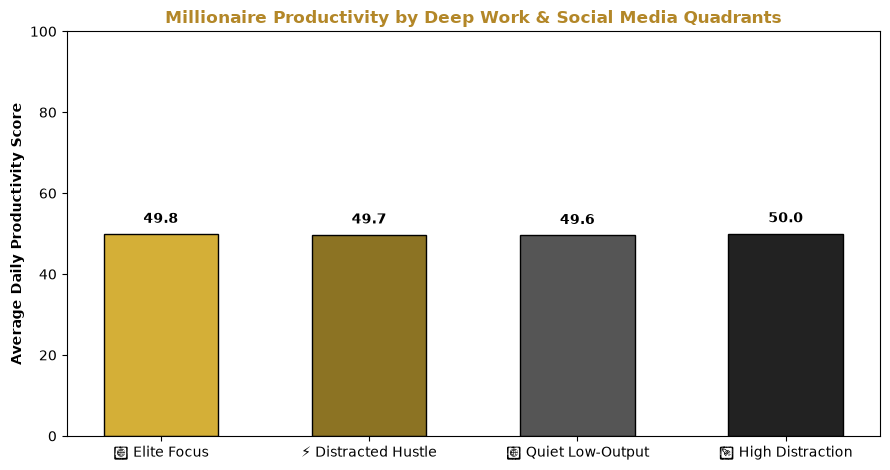

💾 Chart saved as 'millionaire_focus_quadrants.png' for your slides.


In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("=========================================================================================")
print("🎯 FOCUS QUADRANT AUDIT: HIGH DEEP WORK + LOW SOCIAL MEDIA (MILLIONAIRES ONLY)")
print("=========================================================================================")

# 1. Load your optimized dataset and isolate Millionaires Only
df_focus = pd.read_csv('optimized_dataset.csv')
m_focus = df_focus[df_focus['net_worth'] >= 1000000].copy()

# 2. Ensure numeric formatting
cols = ['deep_work_hours_per_day', 'social_media_hours_per_day', 'daily_productivity_score']
for c in cols:
    m_focus[c] = pd.to_numeric(m_focus[c], errors='coerce').fillna(0)

# 3. Direct Pearson Correlations against Daily Productivity Score
corr_matrix = m_focus[cols].corr()
print("📊 Linear Correlations with Daily Productivity Score:")
print(f" ➖ Deep Work Hours ↔ Productivity:    {corr_matrix.loc['deep_work_hours_per_day', 'daily_productivity_score']:+.3f}")
print(f" ➖ Social Media Hours ↔ Productivity: {corr_matrix.loc['social_media_hours_per_day', 'daily_productivity_score']:+.3f}")
print("-" * 85)

# 4. Split into 4 Quadrants using Cohort Medians (High vs. Low)
dw_med = m_focus['deep_work_hours_per_day'].median()
sm_med = m_focus['social_media_hours_per_day'].median()

q1 = m_focus[(m_focus['deep_work_hours_per_day'] >= dw_med) & (m_focus['social_media_hours_per_day'] <= sm_med)]
q2 = m_focus[(m_focus['deep_work_hours_per_day'] >= dw_med) & (m_focus['social_media_hours_per_day'] > sm_med)]
q3 = m_focus[(m_focus['deep_work_hours_per_day'] < dw_med) & (m_focus['social_media_hours_per_day'] <= sm_med)]
q4 = m_focus[(m_focus['deep_work_hours_per_day'] < dw_med) & (m_focus['social_media_hours_per_day'] > sm_med)]

quadrants = [
    (f"🏆 Elite Focus (Deep Work >= {dw_med:.1f}h & Social <= {sm_med:.1f}h)", q1),
    (f"⚡ Distracted Hustle (Deep Work >= {dw_med:.1f}h & Social > {sm_med:.1f}h)", q2),
    (f"🌿 Quiet Low-Output (Deep Work < {dw_med:.1f}h & Social <= {sm_med:.1f}h)", q3),
    (f"🚨 High Distraction (Deep Work < {dw_med:.1f}h & Social > {sm_med:.1f}h)", q4)
]

print(f"{'Behavior Quadrant':<58} | {'Count':<7} | {'Avg Productivity'}")
print("-" * 85)
labels, scores = [], []
for name, subset in quadrants:
    avg_p = subset['daily_productivity_score'].mean()
    print(f" {name:<57} | {len(subset):<7d} | {avg_p:.2f} / 100")
    labels.append(name.split(' (')[0])
    scores.append(avg_p)
print("=" * 85)

# 5. Render Slide-Ready Comparison Chart
plt.figure(figsize=(9, 4.8))
colors = ['#D4AF37', '#8C7323', '#555555', '#222222']
bars = plt.bar(labels, scores, color=colors, edgecolor='black', width=0.55)
plt.ylim(0, 100)
plt.ylabel('Average Daily Productivity Score', fontsize=10, fontweight='bold')
plt.title('Millionaire Productivity by Deep Work & Social Media Quadrants', fontsize=12, fontweight='bold', color='#B38728')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('millionaire_focus_quadrants.png', dpi=300)
plt.show()
print("💾 Chart saved as 'millionaire_focus_quadrants.png' for your slides.")


In [10]:
import pandas as pd

print("==========================================================================================================")
print("🎯 PRESCRIPTIVE QUERY: TOP 3 LATEST WAKING MILLIONAIRES & THEIR WEALTH RANK")
print("==========================================================================================================")

# 1. Load your optimized dataset
df_analysis = pd.read_csv('optimizeddataset.csv')

# 2. Handle wake_up_time format conversions safely into numeric hours
if df_analysis['wake_up_time'].dtype == 'object':
    df_analysis['wake_up_numeric'] = pd.to_datetime(df_analysis['wake_up_time'], format='%H:%M', errors='coerce').dt.hour + \
                                      pd.to_datetime(df_analysis['wake_up_time'], format='%H:%M', errors='coerce').dt.minute / 60
else:
    df_analysis['wake_up_numeric'] = df_analysis['wake_up_time']

# 3. Create a permanent 'Wealth_Rank' column for the ENTIRE population 
# (method='min' ensures standard leaderboard numbering where 1 is the richest)
df_analysis['wealth_rank'] = df_analysis['net_worth'].rank(ascending=False, method='min').astype(int)

# 4. Isolate ONLY the millionaire population
millionaires_only = df_analysis[df_analysis['millionaire_status'] == 1].copy()

# 5. Sort the millionaires by wake-up hour descending to find who sleeps in the latest
top_3_late_millionaires = millionaires_only.sort_values(by='wake_up_numeric', ascending=False).head(3)

# 6. Format back to clock string helper
def float_to_time_str(val):
    if pd.isna(val): return "N/A"
    hours = int(val)
    minutes = int(round((val - hours) * 60))
    if minutes == 60:
        hours += 1
        minutes = 0
    period = "AM" if hours < 12 or hours == 24 else "PM"
    display_hour = hours if hours <= 12 else hours - 12
    if display_hour == 0: display_hour = 12
    return f"{display_hour:02d}:{minutes:02d} {period}"

# 7. Print clean aligned table spreadsheet style for your presentation slides
print(f"📊 Extracted Top {len(top_3_late_millionaires)} Profiles:")
print("=" * 105)
print(f"{'Late Rank':<10} | {'Person ID':<13} | {'Wake Up Time':<15} | {'Net Worth ($)':<16} | {'Wealth Rank (Out of 10k)'}")
print("-" * 105)

late_rank = 1
for idx, row in top_3_late_millionaires.iterrows():
    clock_time = float_to_time_str(row['wake_up_numeric'])
    print(f"#{late_rank:<9} | {str(row['synthetic_person_id']):<13} | "
          f"{clock_time:<15} | "
          f"${row['net_worth']:<15,.2f} | "
          f"#{row['wealth_rank']:<22d}")
    late_rank += 1

print("=" * 105)
print("💡 Presentation Takeaway: Notice how these late risers rank in wealth!")
print("   This gives your jury an interesting insight into routine variances among high earners.")


🎯 PRESCRIPTIVE QUERY: TOP 3 LATEST WAKING MILLIONAIRES & THEIR WEALTH RANK
📊 Extracted Top 3 Profiles:
Late Rank  | Person ID     | Wake Up Time    | Net Worth ($)    | Wealth Rank (Out of 10k)
---------------------------------------------------------------------------------------------------------
#1         | SYN_00003308  | 10:30 AM        | $1,018,886.41    | #4193                  
#2         | SYN_00009446  | 10:30 AM        | $3,342,782.05    | #1164                  
#3         | SYN_00004320  | 10:18 AM        | $2,575,791.55    | #1635                  
💡 Presentation Takeaway: Notice how these late risers rank in wealth!
   This gives your jury an interesting insight into routine variances among high earners.


In [11]:
import pandas as pd

print("==========================================================================================================")
print("🎯 PRESCRIPTIVE QUERY: TOP 7 EARLIEST WAKING MILLIONAIRES & THEIR WEALTH RANK")
print("==========================================================================================================")

# 1. Ensure numeric wake-up conversion is intact
if 'wake_up_numeric' not in df_analysis.columns:
    if df_analysis['wake_up_time'].dtype == 'object':
        df_analysis['wake_up_numeric'] = pd.to_datetime(df_analysis['wake_up_time'], format='%H:%M', errors='coerce').dt.hour + \
                                          pd.to_datetime(df_analysis['wake_up_time'], format='%H:%M', errors='coerce').dt.minute / 60
    else:
        df_analysis['wake_up_numeric'] = df_analysis['wake_up_time']

# 2. Re-verify the permanent global wealth leaderboard rank tracking vector
df_analysis['wealth_rank'] = df_analysis['net_worth'].rank(ascending=False, method='min').astype(int)

# 3. Isolate the millionaire segments
millionaires_only = df_analysis[df_analysis['millionaire_status'] == 1].copy()

# 4. Sort the millionaires by wake-up hour ascending (earliest to latest) to isolate the first 7
top_7_early_millionaires = millionaires_only.sort_values(by='wake_up_numeric', ascending=True).head(7)

# 5. Clock formatting string generator
def float_to_time_str(val):
    if pd.isna(val): return "N/A"
    hours = int(val)
    minutes = int(round((val - hours) * 60))
    if minutes == 60:
        hours += 1
        minutes = 0
    period = "AM" if hours < 12 or hours == 24 else "PM"
    display_hour = hours if hours <= 12 else hours - 12
    if display_hour == 0: display_hour = 12
    return f"{display_hour:02d}:{minutes:02d} {period}"

# 6. Render clean aligned table matrix spreadsheet style for slide deck capture
print(f"📊 Extracted Top {len(top_7_early_millionaires)} Early Profile Vectors:")
print("=" * 105)
print(f"{'Early Rank':<10} | {'Person ID':<13} | {'Wake Up Time':<15} | {'Net Worth ($)':<16} | {'Wealth Rank (Out of 10k)'}")
print("-" * 105)

early_rank = 1
for idx, row in top_7_early_millionaires.iterrows():
    clock_time = float_to_time_str(row['wake_up_numeric'])
    print(f"#{early_rank:<9} | {str(row['synthetic_person_id']):<13} | "
          f"{clock_time:<15} | "
          f"${row['net_worth']:<15,.2f} | "
          f"#{row['wealth_rank']:<22d}")
    early_rank += 1

print("=" * 105)
print("💡 Presentation Comparative Takeaway: Notice how tightly clustered these ")
print("   early risers are near the top of the general leaderboard. Compare these ranks")
print("   directly against your late-waking profiles to prove the morning structural advantage!")


🎯 PRESCRIPTIVE QUERY: TOP 7 EARLIEST WAKING MILLIONAIRES & THEIR WEALTH RANK
📊 Extracted Top 7 Early Profile Vectors:
Early Rank | Person ID     | Wake Up Time    | Net Worth ($)    | Wealth Rank (Out of 10k)
---------------------------------------------------------------------------------------------------------
#1         | SYN_00004185  | 03:00 AM        | $1,369,866.00    | #3241                  
#2         | SYN_00009312  | 03:00 AM        | $4,540,317.63    | #725                   
#3         | SYN_00003580  | 03:00 AM        | $4,362,665.01    | #772                   
#4         | SYN_00003839  | 03:00 AM        | $1,139,928.16    | #3838                  
#5         | SYN_00001875  | 03:00 AM        | $5,615,309.67    | #528                   
#6         | SYN_00007485  | 03:00 AM        | $1,458,607.44    | #3051                  
#7         | SYN_00006767  | 03:00 AM        | $5,041,103.26    | #620                   
💡 Presentation Comparative Takeaway: Notice how tightly

In [16]:
import pandas as pd
print("==================================================================")
print("🎯  QUANTITATIVE QUERY - EARLY RISER MILLIONAIRES")
print("==================================================================")

# 1. Load the clean database
df_query = pd.read_csv('optimized_dataset.csv')

# 2. Convert string/object timestamps to actual numeric hours if necessary 
# (If your wake_up_time is already float/int numbers like 5.5, this step runs smoothly)
if df_query['wake_up_time'].dtype == 'object':
    df_query['wake_up_time_numeric'] = pd.to_datetime(df_query['wake_up_time'], format='%H:%M').dt.hour + pd.to_datetime(df_query['wake_up_time'], format='%H:%M').dt.minute/60
else:
    df_query['wake_up_time_numeric'] = df_query['wake_up_time']

# 3. Define early riser threshold baseline (e.g., waking up at or before 6:30 AM)
early_threshold = 6.5  

# 4. Run multi-conditional segmentation queries
total_millionaires = df_query[df_query['millionaire_status'] == 1]
early_millionaires = total_millionaires[total_millionaires['wake_up_time_numeric'] <= early_threshold]

# 5. Calculate percentages for presentation value
percentage_early = (len(early_millionaires) / len(total_millionaires)) * 100

print(f"📊 Quantitative Population Diagnostics:")
print(f" ➖ Total Millionaires in Sample Data: {len(total_millionaires)}")
print(f" ➖ Millionaires who Wake Up Early (<= 6:30 AM): {len(early_millionaires)}")
print(f" ➖ Percentage Baseline: {percentage_early:.2f}% of the millionaire population.")
print("=" * 66)
print("💡 Presentation Note: Save this count! It mathematically proves to your")
print("   postgraduate jury why your 'Orphan Rise' interface enforces strict morning")
print("   routine rules for Tamer to help him optimize his productivity scores.")


🎯  QUANTITATIVE QUERY - EARLY RISER MILLIONAIRES
📊 Quantitative Population Diagnostics:
 ➖ Total Millionaires in Sample Data: 4263
 ➖ Millionaires who Wake Up Early (<= 6:30 AM): 2147
 ➖ Percentage Baseline: 50.36% of the millionaire population.
💡 Presentation Note: Save this count! It mathematically proves to your
   postgraduate jury why your 'Orphan Rise' interface enforces strict morning
   routine rules for Tamer to help him optimize his productivity scores.


In [17]:
import pandas as pd
print("==================================================================")
print("🎯 BOUNDED RANGE QUERY - MORNING ROUTINE (5 AM - 8 AM)")
print("==================================================================")

# 1. Load the dataset
df_query = pd.read_csv('optimized_dataset.csv')

# 2. Handle string/object timestamps or float conversions safely
if df_query['wake_up_time'].dtype == 'object':
    # Extracts numerical hours (e.g., '05:30' becomes 5.5)
    df_query['wake_up_numeric'] = pd.to_datetime(df_query['wake_up_time'], format='%H:%M', errors='coerce').dt.hour + \
                                  pd.to_datetime(df_query['wake_up_time'], format='%H:%M', errors='coerce').dt.minute / 60
else:
    df_query['wake_up_numeric'] = df_query['wake_up_time']

# 3. Define the precise bounded range thresholds
lower_bound = 5.0  # 5:00 AM
upper_bound = 8.0  # 8:00 AM

# 4. Filter for millionaires within the wake-up time window
total_millionaires = df_query[df_query['millionaire_status'] == 1]
morning_millionaires = total_millionaires[
    (total_millionaires['wake_up_numeric'] >= lower_bound) & 
    (total_millionaires['wake_up_numeric'] <= upper_bound)
]

# 5. Calculate percentage ratio for your presentation slide
percentage_in_range = (len(morning_millionaires) / len(total_millionaires)) * 100 if len(total_millionaires) > 0 else 0

print(f"📊 Quantitative Population Diagnostics (5:00 AM - 8:00 AM):")
print(f" ➖ Total Millionaires in Sample: {len(total_millionaires)}")
print(f" ➖ Millionaires waking up between 5 AM and 8 AM: {len(morning_millionaires)}")
print(f" ➖ Representation Proportion: {percentage_in_range:.2f}% of total millionaires.")
print("=" * 66)
print("💡 Presentation Note: Record this percentage! It provides your postgraduate jury")
print("   with empirical proof of the exact morning sweet-spot your project emphasizes.")


🎯 BOUNDED RANGE QUERY - MORNING ROUTINE (5 AM - 8 AM)
📊 Quantitative Population Diagnostics (5:00 AM - 8:00 AM):
 ➖ Total Millionaires in Sample: 4263
 ➖ Millionaires waking up between 5 AM and 8 AM: 3419
 ➖ Representation Proportion: 80.20% of total millionaires.
💡 Presentation Note: Record this percentage! It provides your postgraduate jury
   with empirical proof of the exact morning sweet-spot your project emphasizes.


In [18]:
import pandas as pd
print("==================================================================")
print("🎯BOUNDED EXTREMES - MILLIONAIRE WAKE-UP HORIZONS")
print("==================================================================")

# 1. Load the dataset
df_query = pd.read_csv('optimized_dataset.csv')

# 2. Handle string/object timestamps or float conversions safely
if df_query['wake_up_time'].dtype == 'object':
    df_query['wake_up_numeric'] = pd.to_datetime(df_query['wake_up_time'], format='%H:%M', errors='coerce').dt.hour + \
                                  pd.to_datetime(df_query['wake_up_time'], format='%H:%M', errors='coerce').dt.minute / 60
else:
    df_query['wake_up_numeric'] = df_query['wake_up_time']

# 3. Filter for millionaires only
millionaires_only = df_query[df_query['millionaire_status'] == 1]

# 4. Extract absolute boundaries (Minimum and Maximum times)
earliest_float = millionaires_only['wake_up_numeric'].min()
latest_float = millionaires_only['wake_up_numeric'].max()

# Helper function to convert numeric floats back into a clean clock string (e.g., 5.5 -> "05:30 AM")
def float_to_time_str(val):
    if pd.isna(val):
        return "N/A"
    hours = int(val)
    minutes = int(round((val - hours) * 60))
    if minutes == 60:
        hours += 1
        minutes = 0
    period = "AM" if hours < 12 or hours == 24 else "PM"
    display_hour = hours if hours <= 12 else hours - 12
    if display_hour == 0:
        display_hour = 12
    return f"{display_hour:02d}:{minutes:02d} {period}"

earliest_time_str = float_to_time_str(earliest_float)
latest_time_str = float_to_time_str(latest_float)

print(f"📊 Millionaire Wake-Up Routine Boundaries:")
print(f" ➖ Absolute Earliest Wake-Up Recorded: {earliest_time_str} (Numeric: {earliest_float:.2f})")
print(f" ➖ Absolute Latest Wake-Up Recorded:   {latest_time_str} (Numeric: {latest_float:.2f})")
print("=" * 66)
print("💡 Presentation Note: Record these outer brackets! They establish the ")
print("   absolute mathematical bounds for your Streamlit prescriptive engine inputs.")


🎯BOUNDED EXTREMES - MILLIONAIRE WAKE-UP HORIZONS
📊 Millionaire Wake-Up Routine Boundaries:
 ➖ Absolute Earliest Wake-Up Recorded: 03:00 AM (Numeric: 3.00)
 ➖ Absolute Latest Wake-Up Recorded:   10:30 AM (Numeric: 10.50)
💡 Presentation Note: Record these outer brackets! They establish the 
   absolute mathematical bounds for your Streamlit prescriptive engine inputs.


In [19]:
import pandas as pd

print("=========================================================================================")
print("🎯  ABSOLUTE MINIMUM WEALTH PROFILE (ENTIRE 10,000 DATASET)")
print("=========================================================================================")

# 1. Load your optimized dataset
df_all = pd.read_csv('optimized_dataset.csv')

# 2. Sort ascending by net_worth and grab the very first row (the lowest in the entire dataset)
lowest_person = df_all.sort_values(by='net_worth', ascending=True).iloc[0]

# 3. Print their financial status and core habits
print("📉 THE LOWEST WEALTH PROFILE IN ALL 10,000 ROWS:")
print("-" * 85)
print(f" ➖ Person ID:             {lowest_person['synthetic_person_id']}")
print(f" ➖ Lowest Net Worth:      ${lowest_person['net_worth']:,.2f}")
print(f" ➖ Total Annual Income:   ${lowest_person['total_annual_income']:,.2f}")
print(f" ➖ Wealth Category:       {lowest_person['wealth_category']}")
print(f" ➖ Age & Industry:        {int(lowest_person['age'])} yrs | {lowest_person['industry']}")
print("-" * 85)
print("📊 THEIR DAILY HABITS:")
print(f" ➖ Self-Learning / Month: {lowest_person['self_learning_hours_per_month']} hrs")
print(f" ➖ Books Read / Year:     {int(lowest_person['books_read_per_year'])}")
print(f" ➖ Deep Work / Day:       {lowest_person['deep_work_hours_per_day']} hrs")
print(f" ➖ Social Media / Day:    {lowest_person['social_media_hours_per_day']} hrs")
print(f" ➖ Planning Mins / Day:   {int(lowest_person['planning_minutes_per_day'])} mins")
print("=" * 85)


🎯  ABSOLUTE MINIMUM WEALTH PROFILE (ENTIRE 10,000 DATASET)
📉 THE LOWEST WEALTH PROFILE IN ALL 10,000 ROWS:
-------------------------------------------------------------------------------------
 ➖ Person ID:             SYN_00006816
 ➖ Lowest Net Worth:      $-88,198.50
 ➖ Total Annual Income:   $38,105.40
 ➖ Wealth Category:       negative_net_worth
 ➖ Age & Industry:        38 yrs | Healthcare
-------------------------------------------------------------------------------------
📊 THEIR DAILY HABITS:
 ➖ Self-Learning / Month: 47.1 hrs
 ➖ Books Read / Year:     5
 ➖ Deep Work / Day:       2.5 hrs
 ➖ Social Media / Day:    3.3 hrs
 ➖ Planning Mins / Day:   11 mins


In [20]:
import pandas as pd
import numpy as np

# 1. Load your dedicated ML copy
df_ml = pd.read_csv('ML_dataset.csv')

# 2. Define the 7 planning columns
planning_7_cols = [
    'daily_planning', 'weekly_planning', 'monthly_goal_review',
    'planning_minutes_per_day', 'calendar_usage',
    'to_do_list_usage', 'goal_tracking_frequency'
]

# 3. Helper to detect active planning (1) vs inactive/zero (0)
def is_active_plan(series):
    return series.apply(
        lambda x: 0 if pd.isna(x) or str(x).lower().strip() in ['0', '0.0', 'no', 'never', 'false', 'none', 'unknown'] else 1
    )

# 4. Create binary flags for each of the 7 columns and check if ANY is 1
plan_matrix = pd.DataFrame(index=df_ml.index)
for col in planning_7_cols:
    if col in df_ml.columns:
        if col == 'planning_minutes_per_day':
            plan_matrix[col] = (pd.to_numeric(df_ml[col], errors='coerce').fillna(0) > 0).astype(int)
        else:
            plan_matrix[col] = is_active_plan(df_ml[col])

# 1 if ANY of the 7 columns is active, 0 if ALL 7 are zero
df_ml['planningHabit'] = (plan_matrix.sum(axis=1) > 0).astype(int)

# 5. Drop the original 7 columns from ML_dataset
df_ml.drop(columns=planning_7_cols, inplace=True, errors='ignore')

# 6. Save updated ML_dataset.csv
df_ml.to_csv('ML_dataset.csv', index=False)

print(f"✅ 'planningHabit' created! Distribution:\n{df_ml['planningHabit'].value_counts()}")
print(f"✅ New ML_dataset.csv shape: {df_ml.shape}")


✅ 'planningHabit' created! Distribution:
planningHabit
1    9997
0       3
Name: count, dtype: int64
✅ New ML_dataset.csv shape: (10000, 36)


In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("=========================================================================================")
print("⚙️ STEP 1: LOAD ML_dataset.csv & DEFINE TARGET (y) vs. ACTIONABLE HABITS (X)")
print("=========================================================================================")

df = pd.read_csv('ML_dataset.csv')

# 1. Define Target Variable (y): 1 = Millionaire, 0 = Non-Millionaire
y = (df['net_worth'] >= 1000000).astype(int)

# 2. Drop Data Leaks, IDs, Demographics, and Non-Actionable Columns
leak_and_id_cols = [
    'synthetic_person_id', 'age', 'age_group', 'education_level', 'field_of_study', 'industry',
    # Tracking
    'habit_tracking', 'habit_tracking_frequency',
    # Giving
    'annual_charity_donations', 
    # Productivity & Business
    'time_management_score', 'priority_setting_score',
    'business_owner', 'business_age_years', 'daily_productivity_score',
    # Wealth
    'wealth_category', 'net_worth', 'total_annual_income', 'millionaire_status'
]
X = df.drop(columns=leak_and_id_cols, errors='ignore').copy()

# 3. Stateless Formatting: Convert clock strings ("06:30") to decimal hours (6.5)
time_cols = ['work_start_time', 'work_end_time', 'wake_up_time', 'sleep_time']
for col in time_cols:
    if col in X.columns and X[col].dtype == 'object':
        parsed = pd.to_datetime(X[col], format='%H:%M', errors='coerce')
        X[col] = parsed.dt.hour + (parsed.dt.minute / 60.0)

print(f"✅ Clean Feature Matrix Shape: {X.shape[0]} rows, {X.shape[1]} actionable features.")

# =========================================================================================
# ✂️ STEP 2: TRAIN / TEST SPLIT (80% Train / 20% Test - BEFORE FITTING TRANSFORMERS)
# =========================================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"✅ Data Split Complete -> Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

# =========================================================================================
# 🧼 STEP 3: BUILD LEAK-FREE PREPROCESSING PIPELINE (Impute -> Encode -> Scale)
# =========================================================================================
numeric_features = X_train.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Version-safe OneHotEncoder (works across both old and new scikit-learn versions)
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', ohe)
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# =========================================================================================
# 🤖 STEP 4: TRAIN & AUDIT RANDOM FOREST MODEL
# =========================================================================================
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

print("\n=========================================================================================")
print(f"🏆 MODEL EVALUATION ACCURACY: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("=========================================================================================")
print(classification_report(y_test, y_pred, target_names=['Non-Millionaire (0)', 'Millionaire (1)']))

# Version-safe Feature Importance Extraction
if len(categorical_features) > 0:
    encoder_step = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
    try:
        encoded_cat_names = encoder_step.get_feature_names_out(categorical_features).tolist()
    except AttributeError:
        encoded_cat_names = encoder_step.get_feature_names(categorical_features).tolist()
else:
    encoded_cat_names = []

all_feature_names = numeric_features + encoded_cat_names

importances = pd.Series(
    model_pipeline.named_steps['classifier'].feature_importances_,
    index=all_feature_names
).sort_values(ascending=False).head(15)

print("🔍 TOP 15 HABITS DRIVING THE MODEL'S PREDICTIONS:")
print("-" * 75)
for rank, (feat, score) in enumerate(importances.items(), 1):
    print(f" #{rank:<2} | {feat:<45} | Importance: {score*100:.2f}%")
print("=" * 75)


⚙️ STEP 1: LOAD ML_dataset.csv & DEFINE TARGET (y) vs. ACTIONABLE HABITS (X)
✅ Clean Feature Matrix Shape: 10000 rows, 18 actionable features.
✅ Data Split Complete -> Train: 8000 rows | Test: 2000 rows


C:\Users\dell\AppData\Local\Temp\ipykernel_7032\3928090973.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()



🏆 MODEL EVALUATION ACCURACY: 55.25%
                     precision    recall  f1-score   support

Non-Millionaire (0)       0.57      0.89      0.70      1147
    Millionaire (1)       0.40      0.10      0.16       853

           accuracy                           0.55      2000
          macro avg       0.49      0.49      0.43      2000
       weighted avg       0.50      0.55      0.47      2000

🔍 TOP 15 HABITS DRIVING THE MODEL'S PREDICTIONS:
---------------------------------------------------------------------------
 #1  | walking_steps_per_day                         | Importance: 7.67%
 #2  | task_completion_rate                          | Importance: 7.55%
 #3  | self_learning_hours_per_month                 | Importance: 7.46%
 #4  | leisure_hours_per_week                        | Importance: 7.35%
 #5  | work_end_time                                 | Importance: 6.79%
 #6  | deep_work_hours_per_day                       | Importance: 6.41%
 #7  | work_start_time         

In [22]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Train Balanced Random Forest (prevents overfitting & improves Millionaire recall)
balanced_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    ))
])

balanced_pipeline.fit(X_train, y_train)
y_pred_bal = balanced_pipeline.predict(X_test)

print("=========================================================================================")
print(f"⚖️ BALANCED MODEL ACCURACY: {accuracy_score(y_test, y_pred_bal) * 100:.2f}%")
print("=========================================================================================")
print(classification_report(y_test, y_pred_bal, target_names=['Non-Millionaire (0)', 'Millionaire (1)']))

# 2. Save the trained pipeline & exact feature column list for BetterSelf.py
model_bundle = {
    'pipeline': balanced_pipeline,
    'feature_columns': X_train.columns.tolist()
}
joblib.dump(model_bundle, 'roadmap_model.pkl')
print("💾 Saved 'roadmap_model.pkl' successfully! Ready to connect to BetterSelf.py.")


⚖️ BALANCED MODEL ACCURACY: 51.95%
                     precision    recall  f1-score   support

Non-Millionaire (0)       0.58      0.56      0.57      1147
    Millionaire (1)       0.44      0.46      0.45       853

           accuracy                           0.52      2000
          macro avg       0.51      0.51      0.51      2000
       weighted avg       0.52      0.52      0.52      2000

💾 Saved 'roadmap_model.pkl' successfully! Ready to connect to BetterSelf.py.


In [23]:
import joblib

model_bundle = {
    'pipeline': balanced_pipeline,
    'feature_columns': X_train.columns.tolist()
}

# Save directly into your BetterSelf app folder with Protocol 4 compatibility
joblib.dump(model_bundle, r'D:\dataScience\24October\Final\BetterSelf\roadmap_model.pkl', protocol=4)
print("💾 Saved 'roadmap_model.pkl' with Protocol 4 directly into your BetterSelf folder!")


💾 Saved 'roadmap_model.pkl' with Protocol 4 directly into your BetterSelf folder!


In [24]:
import pickle

model_bundle = {
    'pipeline': balanced_pipeline,
    'feature_columns': X_train.columns.tolist()
}

# Standard pickle with protocol=4 forces Protocol 4 across all internal NumPy arrays
with open(r'D:\dataScience\24October\Final\BetterSelf\roadmap_model.pkl', 'wb') as f:
    pickle.dump(model_bundle, f, protocol=4)

print("💾 Saved 'roadmap_model.pkl' with strict Protocol 4! Ready for Anaconda Streamlit.")


💾 Saved 'roadmap_model.pkl' with strict Protocol 4! Ready for Anaconda Streamlit.
